In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
import warnings

In [3]:
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("air_quality_india.csv")

In [5]:
df.sample(4)

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,nox,nh3,so2,co,ozone,benzene,toluene,aqi,aqi_category,pm2_5_ugm3
4041,2025-04-17,MB-02,Mumbai,Traffic,12.0,14060.0,26.0,44,5.3,28.1,...,-,-,-,-,-,-,-,NaN,NaN,-
9535,2025-12-01,BL-02,Bengaluru,Traffic,916.0,3245.0,58.0,37,8.7,20.5,...,43.7,27.5,4.3,1.42,35.1,5.25,8.92,91.0,Satisfactory,54.7
14818,2026-07-08,MB-03,Mumbai,Industrial,4.0,25661.0,571.0,144,3.6,27.5,...,35.6,14.2,31.5,0.54,25.0,3.18,5.06,55.0,Satisfactory,13.4
12189,2026-03-21,CH-01,Chennai,Residential,8.0,27715.0,84.0,22,10.9,28.2,...,PowerFail,PowerFail,PowerFail,PowerFail,PowerFail,PowerFail,PowerFail,NaN,NaN,PowerFail


In [6]:
df.dtypes

date                            object
station_id                      object
city                            object
station_type                    object
elevation_m                    float64
population_density_per_km2     float64
distance_to_major_road_m       float64
industrial_units_within_5km      int64
green_cover_pct                float64
temperature_c                  float64
relative_humidity_pct          float64
wind_speed_ms                  float64
wind_direction_deg             float64
pressure_hpa                   float64
rainfall_mm                    float64
solar_radiation_wm2            float64
boundary_layer_height_m        float64
visibility_km                  float64
upwind_fire_count              float64
festival_flag                    int64
holiday_flag                     int64
dust_alert                      object
pm10                            object
no                              object
no2                             object
nox                      

In [7]:
df.shape

(17600, 35)

In [8]:
df.duplicated().sum()

76

In [9]:
#removed duplicate rows (absolute duplicates - 76 of them)
df = df.drop_duplicates()

In [10]:
df = df.reset_index().drop("index", axis = 1)
df.shape

(17524, 35)

### Looking at the DATE column - multiple formats found

In [11]:
df["date"].sample(5)

16894    2026-10-05
6439     2025-07-27
14429    2026-06-25
15861    2026-08-23
10510    2026-01-12
Name: date, dtype: object

In [12]:
df["date"].str[4].value_counts()

-    16986
2       92
1       79
5       57
4       49
6       46
8       46
3       45
0       44
7       40
9       40
Name: date, dtype: int64

In [13]:
df["date"].str[2].value_counts()

2    16986
/      538
Name: date, dtype: int64

In [14]:
sum([92,79,57,49,46,46,45,44,40,40])

538

In [15]:
#separated the dataset into the two date formats identified
df1 = df[df["date"].str[2] == "/"]

In [16]:
df1["date"]

15       01/11/2024
16       01/11/2024
21       01/11/2024
70       03/11/2024
117      05/11/2024
            ...    
17215    19/10/2026
17341    24/10/2026
17356    25/10/2026
17366    25/10/2026
17387    26/10/2026
Name: date, Length: 538, dtype: object

In [17]:
df1["date"] = pd.to_datetime(df1["date"], format = "%d/%m/%Y")

In [18]:
df2 = df[df["date"].str[2] != "/"]

In [19]:
df2["date"].str[4].value_counts()

-    16986
Name: date, dtype: int64

In [20]:
df2.head()

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,nox,nh3,so2,co,ozone,benzene,toluene,aqi,aqi_category,pm2_5_ugm3
0,2024-11-01,DL-01,Delhi,Residential,212.0,8848.0,241.0,57,19.5,15.5,...,44.6,43.4,5.7,0.9,36.4,2.65,5.12,378.0,Very Poor,220.9
1,2024-11-01,DL-02,Delhi,Roadside,211.0,9231.0,58.0,45,5.2,15.9,...,62.8,27.1,5.9,1.62,35.2,NaN,NaN,400.0,Severe,250.6
2,2024-11-01,DL-03,Delhi,Background,220.0,14732.0,2647.0,13,20.2,15.4,...,29.0,28.0,1.9,0.56,50.7,NaN,NaN,344.0,Very Poor,177.2
3,2024-11-01,LK-01,Lucknow,Residential,126.0,2206.0,172.0,28,15.0,18.8,...,47.5,69.2,6.4,1.65,33.3,1.59,4.8,500.0,Severe,388.1
4,2024-11-01,LK-02,Lucknow,Traffic,124.0,2678.0,45.0,30,8.0,19.2,...,96.1,NaN,14.7,2.82,41.6,7.05,20.51,500.0,Severe,392.6


In [21]:
df2["date"] = pd.to_datetime(df2["date"])

In [22]:
df2.head()

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,nox,nh3,so2,co,ozone,benzene,toluene,aqi,aqi_category,pm2_5_ugm3
0,2024-11-01,DL-01,Delhi,Residential,212.0,8848.0,241.0,57,19.5,15.5,...,44.6,43.4,5.7,0.9,36.4,2.65,5.12,378.0,Very Poor,220.9
1,2024-11-01,DL-02,Delhi,Roadside,211.0,9231.0,58.0,45,5.2,15.9,...,62.8,27.1,5.9,1.62,35.2,NaN,NaN,400.0,Severe,250.6
2,2024-11-01,DL-03,Delhi,Background,220.0,14732.0,2647.0,13,20.2,15.4,...,29.0,28.0,1.9,0.56,50.7,NaN,NaN,344.0,Very Poor,177.2
3,2024-11-01,LK-01,Lucknow,Residential,126.0,2206.0,172.0,28,15.0,18.8,...,47.5,69.2,6.4,1.65,33.3,1.59,4.8,500.0,Severe,388.1
4,2024-11-01,LK-02,Lucknow,Traffic,124.0,2678.0,45.0,30,8.0,19.2,...,96.1,NaN,14.7,2.82,41.6,7.05,20.51,500.0,Severe,392.6


In [23]:
df = pd.concat([df1,df2])

In [24]:
df = df.sort_index()

In [25]:
df[df.duplicated()]

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,nox,nh3,so2,co,ozone,benzene,toluene,aqi,aqi_category,pm2_5_ugm3
7582,2025-09-12,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,26.9,...,-,11.2,2.6,0.87,58.6,NaN,NaN,70.0,Satisfactory,41.2
9383,2025-11-26,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,20.8,...,28.6,13.5,5.4,0.7,48.3,NaN,NaN,147.0,Moderate,74.1
9975,2025-12-21,MB-01,Mumbai,Residential,1.0,29074.0,121.0,42,9.6,26.4,...,NoData,17.5,7.7,0.65,39.9,2.57,4.46,67.0,Satisfactory,35.5
15294,2026-07-31,DL-03,Delhi,Background,220.0,14732.0,2647.0,13,20.2,29.3,...,11.7,29.0,2.9,0.53,33.1,NaN,NaN,58.0,Satisfactory,28.6


In [26]:
df[(df["date"] == "2025-09-12") & (df["station_id"] == "HY-01")]

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,nox,nh3,so2,co,ozone,benzene,toluene,aqi,aqi_category,pm2_5_ugm3
7581,2025-09-12,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,26.9,...,-,11.2,2.6,0.87,58.6,NaN,NaN,70.0,Satisfactory,41.2
7582,2025-09-12,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,26.9,...,-,11.2,2.6,0.87,58.6,NaN,NaN,70.0,Satisfactory,41.2


In [27]:
df = df.drop_duplicates()
df = df.reset_index().drop("index", axis = 1)

In [28]:
df.duplicated().sum()

0

In [29]:
df["date"].dt.date

0        2024-11-01
1        2024-11-01
2        2024-11-01
3        2024-11-01
4        2024-11-01
            ...    
17515    2026-10-31
17516    2026-10-31
17517    2026-10-31
17518    2026-10-31
17519    2026-10-31
Name: date, Length: 17520, dtype: object

In [30]:
unique_dates = df["date"].dt.date.unique()

In [31]:
for i in range(1, len(unique_dates)):
    if (unique_dates[i] - unique_dates[i-1]) != (unique_dates[2] - unique_dates[1]):
        print(i, unique_dates[i-1], unique_dates[i])

### Numeric Columns (Type as Objects)

In [32]:
df.dtypes[df.dtypes == "object"]

station_id      object
city            object
station_type    object
dust_alert      object
pm10            object
no              object
no2             object
nox             object
nh3             object
so2             object
co              object
ozone           object
benzene         object
toluene         object
aqi_category    object
pm2_5_ugm3      object
dtype: object

In [33]:
df["station_id"].sample(5)

11578    KL-02
10567    PT-02
2470     HY-02
4854     PT-01
16255    PT-02
Name: station_id, dtype: object

In [34]:
df["city"].sample(5)

12667    Bengaluru
8150        Mumbai
3797       Lucknow
12093    Hyderabad
17465      Chennai
Name: city, dtype: object

In [35]:
df["station_type"].sample(5)

16835     Industrial
16731    Residential
8107         Traffic
7275     Residential
3783     Residential
Name: station_type, dtype: object

In [36]:
df["dust_alert"].sample(5)

9217     No
3429     No
3220     no
884      No
16329    No
Name: dust_alert, dtype: object

In [37]:
df["aqi_category"].value_counts()

Satisfactory    6698
Moderate        3110
Good            2401
Very Poor       1902
Poor            1286
Severe           704
Name: aqi_category, dtype: int64

In [38]:
#Numerics with categories -  should be fully numerics but reasons (words/objects) are included
#pm10, no, no2, nox, nh3, so2, co, ozone, benzene, toluene, pm2_5_ugm3

In [39]:
df_checks = df[["pm10", "no", "no2", "nox", "nh3", "so2", "co", "ozone", "benzene", "toluene", "pm2_5_ugm3"]]

In [40]:
#example
df_checks[df_checks["pm10"] == "-"]

,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
4,-,87.9,52.2,96.1,NaN,14.7,2.82,41.6,7.05,20.51,392.6
274,-,78.5,102.3,118.1,34.5,14.0,2.39,32.8,6.95,17.84,182.7
480,-,34.0,70.5,65.0,33.8,16.9,1.82,18.8,4.83,10.38,357.7
1540,-,28.9,60.7,-,NaN,9.4,2.05,30.2,6.67,12.47,320.9
1621,-,60.0,50.9,71.7,22.2,8.7,1.26,47.8,2.53,7.73,55.0
...,...,...,...,...,...,...,...,...,...,...,...
17166,-,32.0,38.2,44.9,46.9,7.8,1.51,33.1,NaN,NaN,133.0
17383,-,-,-,-,-,-,-,-,-,-,-
17407,-,-,-,-,-,-,-,-,-,-,-
17431,-,-,-,-,-,-,-,-,-,-,-


In [41]:
#Took out all the 'words' from these numerical columns to make it numeric - errors = 'coerce' makes them NaNs (blanks)
for i in df_checks.columns:
    df_checks[i] = pd.to_numeric(df_checks[i], errors='coerce')

In [42]:
#checking the min positive value
df_checks["pm10"][df_checks["pm10"] >= 0].min()

4.7

In [43]:
df_checks.isna().sum()

pm10          1726
no            2449
no2           1815
nox           2450
nh3           5723
so2           1829
co            1877
ozone         3447
benzene       6561
toluene       6554
pm2_5_ugm3    1678
dtype: int64

In [44]:
df_checks = df_checks.replace(-999, np.nan)

In [45]:
df_checks.isna().sum()

pm10          1752
no            2449
no2           1841
nox           2450
nh3           5723
so2           1829
co            1877
ozone         3447
benzene       6561
toluene       6554
pm2_5_ugm3    1678
dtype: int64

In [46]:
#Counts the blanks per ROW
df_checks["Blanks"] = df_checks.isna().sum(axis=1)

In [47]:
df_checks

,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3,Blanks
0,411.5,31.4,35.6,44.6,43.4,5.7,0.90,36.4,2.65,5.12,220.9,0
1,402.5,33.4,71.1,62.8,27.1,5.9,1.62,35.2,NaN,NaN,250.6,2
2,283.6,17.5,25.2,29.0,28.0,1.9,0.56,50.7,NaN,NaN,177.2,2
3,594.4,31.2,42.7,47.5,69.2,6.4,1.65,33.3,1.59,4.80,388.1,0
4,NaN,87.9,52.2,96.1,NaN,14.7,2.82,41.6,7.05,20.51,392.6,2
...,...,...,...,...,...,...,...,...,...,...,...,...
17515,44.3,57.0,60.6,79.4,11.1,4.4,1.94,10.6,4.63,7.38,42.2,0
17516,57.7,25.0,58.4,50.0,NaN,12.0,1013.58,NaN,NaN,NaN,43.2,4
17517,141.5,11.5,18.8,19.5,14.5,3.3,0.78,26.5,NaN,NaN,72.2,2
17518,130.7,56.3,60.8,NaN,NaN,5.7,2.09,36.1,8.73,26.44,79.8,2


In [48]:
df_checks["Blanks"].value_counts()

0     5789
2     4589
1     3375
3     1455
11    1409
4      783
5      108
6       12
Name: Blanks, dtype: int64

In [49]:
df.shape

(17520, 35)

In [50]:
#11 Blanks removed from the main dataset (df)
df = df[~df.index.isin(df_checks[df_checks["Blanks"] == 11].index)]
df = df.reset_index().drop("index", axis = 1)

### Target Column - Removing NAs

In [51]:
df["pm2_5_ugm3"] = pd.to_numeric(df["pm2_5_ugm3"], errors = "coerce")

In [52]:
#target column - dropping where it is NaN because we cannot impute the target column in any case
df["pm2_5_ugm3"].isna().sum()

269

In [53]:
df = df[~df["pm2_5_ugm3"].isna()]
df = df.reset_index().drop("index", axis = 1)

In [54]:
df.shape

(15842, 35)

In [55]:
#these are the negative readings of pm2_5_umg3 (Target Column) and the readings cannot be negative
df = df[df["pm2_5_ugm3"] > 0]
df = df.reset_index().drop("index", axis = 1)

### Removing Columns which are not required (Data Leaks Prevented)

In [56]:
# Dropped 'aqi' and 'aqi_category': they are computed from PM2.5 (the target) and other pollutants, so keeping them would leak the answer into the features (target leakage)
df.drop(["aqi", "aqi_category"], axis = 1, inplace = True)

In [57]:
df_checks.columns[:-1]

Index(['pm10', 'no', 'no2', 'nox', 'nh3', 'so2', 'co', 'ozone', 'benzene',
       'toluene', 'pm2_5_ugm3'],
      dtype='object')

In [58]:
df[df_checks.columns[:-1]]

,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
0,411.5,31.4,35.6,44.6,43.4,5.7,0.9,36.4,2.65,5.12,220.9
1,402.5,33.4,71.1,62.8,27.1,5.9,1.62,35.2,NaN,NaN,250.6
2,283.6,17.5,25.2,29.0,28.0,1.9,0.56,50.7,NaN,NaN,177.2
3,594.4,31.2,42.7,47.5,69.2,6.4,1.65,33.3,1.59,4.8,388.1
4,-,87.9,52.2,96.1,NaN,14.7,2.82,41.6,7.05,20.51,392.6
...,...,...,...,...,...,...,...,...,...,...,...
15747,44.3,57.0,60.6,79.4,11.1,4.4,1.94,10.6,4.63,7.38,42.2
15748,57.7,25.0,58.4,50.0,NaN,12.0,1013.58,NaN,NaN,NaN,43.2
15749,141.5,11.5,18.8,19.5,14.5,3.3,0.78,26.5,NaN,NaN,72.2
15750,130.7,56.3,60.8,NaN,NaN,5.7,2.09,36.1,8.73,26.44,79.8


In [59]:
#Took out all the 'words' from these numerical columns to make it numeric - errors = 'coerce' makes them NaNs (blanks)
for i in df_checks.columns[:-1]:
    df[i] = pd.to_numeric(df[i], errors='coerce')

In [60]:
df.replace(-999, np.nan, inplace = True)

In [61]:
for i in df[df_checks.columns[:-1]].columns:
    df[i][df[df_checks.columns[:-1]][i] < 0] = np.nan

In [62]:
df_checks.columns

Index(['pm10', 'no', 'no2', 'nox', 'nh3', 'so2', 'co', 'ozone', 'benzene',
       'toluene', 'pm2_5_ugm3', 'Blanks'],
      dtype='object')

In [63]:
#checked all the columns one by one
df["toluene"][df[df_checks.columns[:-1]]["toluene"] < 0]

Series([], Name: toluene, dtype: float64)

### Categorical Columns

In [64]:
df[df.dtypes[df.dtypes == "object"].index]

,station_id,city,station_type,dust_alert
0,DL-01,Delhi,Residential,No
1,DL-02,Delhi,Roadside,No
2,DL-03,Delhi,Background,N
3,LK-01,Lucknow,Residential,No
4,LK-02,Lucknow,Traffic,No
...,...,...,...,...
15747,BL-02,Bengaluru,Traffic,No
15748,BL-03,Bengaluru,Industrial,No
15749,HY-01,Hyderabad,Residential,No
15750,HY-02,Hyderabad,Traffic,No


In [65]:
df["station_id"].value_counts()

DL-02    704
PT-01    695
HY-03    687
BL-01    687
KL-01    686
BL-02    685
HY-01    684
PT-03    683
HY-02    678
PT-02    674
MB-02    670
LK-01    668
CH-03    666
MB-03    665
LK-02    660
MB-01    656
KL-03    656
DL-03    647
LK-03    641
DL-01    623
KL-02    606
BL-03    598
CH-02    572
CH-01    561
Name: station_id, dtype: int64

In [66]:
df["station_type"].value_counts()

Residential    5260
Traffic        4749
Background     3324
Industrial     1919
Roadside        262
traffic         238
Name: station_type, dtype: int64

In [67]:
#This has duplicate meaning values - need to club these
df["dust_alert"].value_counts()

No     14676
no       512
N        465
Yes       89
Y          6
yes        4
Name: dust_alert, dtype: int64

In [68]:
#Properly clubbed the outputs to standardize them
df["dust_alert"][df["dust_alert"].isin(["No", "no", "N"])] = "No"
df["dust_alert"][~df["dust_alert"].isin(["No", "no", "N"])] = "Yes"

In [69]:
#Mumbai-mumbai, Bangalore-Bangalore - Bengaluru, Kolkata-Calcutta, Delhi-delhi-New Delhi
df["city"].value_counts()

Patna         2052
Hyderabad     2049
Lucknow       1969
Mumbai        1933
Kolkata       1848
Delhi         1817
Chennai       1799
Bengaluru     1769
Bangalore      150
New Delhi      117
Calcutta       100
mumbai          58
Bangalore       51
delhi           40
Name: city, dtype: int64

In [70]:
df["city"] = df["city"].map(lambda i : i.strip()).map(lambda i : i.title())

In [71]:
df["city"].value_counts()

Patna        2052
Hyderabad    2049
Mumbai       1991
Lucknow      1969
Delhi        1857
Kolkata      1848
Chennai      1799
Bengaluru    1769
Bangalore     201
New Delhi     117
Calcutta      100
Name: city, dtype: int64

In [72]:
df["city"][df["city"].isin(["Kolkata", "Calcutta"])] = "Kolkata"

In [73]:
df["city"][df["city"].isin(["Bengaluru", "Bangalore"])] = "Bengaluru"

In [74]:
df["city"][df["city"].isin(["New Delhi", "Delhi"])] = "Delhi"

In [75]:
#not it is standardized
df["city"].value_counts()

Patna        2052
Hyderabad    2049
Mumbai       1991
Delhi        1974
Bengaluru    1970
Lucknow      1969
Kolkata      1948
Chennai      1799
Name: city, dtype: int64

In [76]:
df["station_type"] = df["station_type"].str.title()

In [77]:
df["station_type"].value_counts()

Residential    5260
Traffic        4987
Background     3324
Industrial     1919
Roadside        262
Name: station_type, dtype: int64

In [78]:
#Roadside to be merged to Traffic
df["station_type"][df["station_type"] == "Roadside"] = "Traffic"

In [79]:
df["station_type"].value_counts()

Residential    5260
Traffic        5249
Background     3324
Industrial     1919
Name: station_type, dtype: int64

In [80]:
#Checking if the mapping is consistent
df.groupby(["city", "station_type"]).count().reset_index()

,city,station_type,date,station_id,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
0,Bengaluru,Industrial,598,598,598,598,598,598,598,592,...,584,575,583,0,583,578,580,0,0,598
1,Bengaluru,Residential,687,687,687,687,687,687,687,682,...,673,669,673,0,664,668,0,669,668,687
2,Bengaluru,Traffic,685,685,685,685,685,685,685,680,...,675,656,662,667,672,663,652,652,656,685
3,Chennai,Background,666,666,666,666,666,666,666,659,...,0,652,0,0,648,653,0,647,639,666
4,Chennai,Residential,561,561,561,561,561,561,561,553,...,545,549,541,0,540,546,545,539,542,561
5,Chennai,Traffic,572,572,572,572,572,572,572,566,...,556,557,561,555,557,556,546,546,552,572
6,Delhi,Background,647,647,647,647,647,647,647,644,...,635,629,631,630,631,628,630,0,0,647
7,Delhi,Residential,623,623,623,623,623,623,623,621,...,613,605,613,616,612,606,593,599,595,623
8,Delhi,Traffic,704,704,704,704,704,704,704,698,...,691,686,687,687,684,681,688,0,0,704
9,Hyderabad,Background,687,687,687,687,687,687,687,680,...,674,673,673,666,663,668,657,658,663,687


In [81]:
df.describe()

,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,relative_humidity_pct,wind_speed_ms,wind_direction_deg,pressure_hpa,...,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
count,15752.000000,15752.000000,15752.000000,15752.000000,15752.000000,15619.000000,15523.000000,15433.000000,15289.000000,15285.000000,...,14735.000000,15329.000000,14738.000000,11559.000000,15342.000000,15295.000000,13779.000000,10696.000000,10706.000000,15752.000000
mean,229.618207,14996.331386,512.772156,40.523172,11.496642,25.458454,69.065773,2.641113,195.582772,985.487092,...,26.872501,37.979542,42.155727,28.134718,9.359692,72.845745,47.260258,3.164610,7.294858,71.817306
std,302.881616,10857.827126,740.273496,32.926386,6.673198,5.466419,14.556839,1.418740,101.617110,35.111964,...,24.071241,27.088564,30.605063,15.779163,12.186193,274.217686,21.982318,2.385563,6.165419,72.767523
min,1.000000,2206.000000,21.000000,6.000000,3.600000,7.800000,25.000000,0.200000,0.000000,895.200000,...,1.300000,3.700000,1.000000,4.800000,0.700000,0.110000,4.000000,0.200000,0.360000,4.500000
25%,7.000000,5013.000000,58.000000,23.000000,5.200000,21.900000,59.000000,1.600000,104.000000,961.500000,...,11.100000,20.100000,20.800000,16.000000,3.400000,0.670000,30.000000,1.360000,2.900000,28.000000
50%,116.000000,14060.000000,224.000000,37.000000,10.900000,25.800000,68.000000,2.300000,218.000000,1001.000000,...,19.800000,32.900000,34.400000,24.200000,5.600000,1.020000,46.500000,2.550000,5.500000,47.500000
75%,493.000000,22914.000000,751.000000,44.000000,15.800000,29.600000,78.000000,3.300000,279.000000,1010.400000,...,34.400000,49.400000,54.100000,36.700000,9.300000,1.570000,64.800000,4.370000,9.790000,88.300000
max,920.000000,44355.000000,2774.000000,144.000000,29.300000,38.700000,99.000000,10.000000,360.000000,1022.900000,...,547.300000,827.800000,532.300000,131.800000,155.800000,2823.230000,114.600000,21.130000,63.410000,2189.400000


### Some real big outliers handling

In [82]:
df[df["co"].isin(df["co"].nlargest(2))]

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,...,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
1006,2024-12-16,BL-03,Bengaluru,Industrial,920.0,4462.0,334.0,94,8.5,23.3,...,43.1,77.7,74.6,NaN,17.6,2748.50,25.8,NaN,NaN,132.5
7717,2025-10-22,BL-03,Bengaluru,Industrial,920.0,4462.0,334.0,94,8.5,22.8,...,41.4,50.8,61.7,NaN,9.4,2823.23,49.6,NaN,NaN,103.9


In [83]:
abs((df["co"] - df["co"].mean()) / df["co"].std())[abs((df["co"] - df["co"].mean()) / df["co"].std()) > 5]

40       5.648229
63       6.042514
85       7.690402
107      6.209097
369      5.565958
           ...   
15549    5.963963
15572    6.169968
15639    7.712757
15682    8.581884
15705    5.134951
Name: co, Length: 140, dtype: float64

In [84]:
abs((df["co"] - df["co"].mean()) / df["co"].std())[abs((df["co"] - df["co"].mean()) / df["co"].std()) > 9]

1006      9.757409
3400      9.723422
7717     10.029930
10171     9.145779
Name: co, dtype: float64

In [85]:
df["co"][abs((df["co"] - df["co"].mean()) / df["co"].std()) > 9]

1006     2748.50
3400     2739.18
7717     2823.23
10171    2580.78
Name: co, dtype: float64

In [86]:
df[df["station_id"] == "BL-01"].mean()

elevation_m                     900.000000
population_density_per_km2     5300.000000
distance_to_major_road_m        499.000000
industrial_units_within_5km      31.000000
green_cover_pct                  29.300000
temperature_c                    23.245748
relative_humidity_pct            70.920236
wind_speed_ms                     3.547774
wind_direction_deg              182.142433
pressure_hpa                    909.455804
rainfall_mm                       3.612817
solar_radiation_wm2                    NaN
boundary_layer_height_m        1010.395924
visibility_km                    16.257165
upwind_fire_count               138.677661
festival_flag                     0.008734
holiday_flag                      0.030568
pm10                             29.753720
no                               15.433581
no2                              26.569357
nox                              26.598960
nh3                                    NaN
so2                               3.466416
co         

In [87]:
df[df["station_id"] == "BL-03"].mean()

elevation_m                     920.000000
population_density_per_km2     4462.000000
distance_to_major_road_m        334.000000
industrial_units_within_5km      94.000000
green_cover_pct                   8.500000
temperature_c                    23.568412
relative_humidity_pct            70.404762
wind_speed_ms                     2.816184
wind_direction_deg              185.037479
pressure_hpa                    907.044274
rainfall_mm                       2.789365
solar_radiation_wm2             181.020408
boundary_layer_height_m        1050.086957
visibility_km                    12.795255
upwind_fire_count               134.626506
festival_flag                     0.010033
holiday_flag                      0.033445
pm10                             59.610274
no                               22.579623
no2                              39.632000
nox                              38.911835
nh3                                    NaN
so2                              17.412350
co         

In [88]:
df.groupby("station_id")["co"].median()

station_id
BL-01       0.780
BL-02       1.440
BL-03    1112.225
CH-01       0.760
CH-02       1.275
CH-03       0.480
DL-01       0.810
DL-02       1.420
DL-03       0.520
HY-01       0.790
HY-02       1.390
HY-03       0.500
KL-01       0.840
KL-02       1.430
KL-03       1.205
LK-01       0.890
LK-02       1.480
LK-03       0.510
MB-01       0.810
MB-02       1.350
MB-03       1.070
PT-01       0.820
PT-02       1.570
PT-03     550.560
Name: co, dtype: float64

In [89]:
def z_score(col):
    return (df[col] - df[col].mean())/df[col].std()

In [90]:
pd.set_option("Display.max_columns", None)

In [91]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns
pd.DataFrame({c: z_score(c).abs().nlargest(5).values for c in num_cols})

,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,relative_humidity_pct,wind_speed_ms,wind_direction_deg,pressure_hpa,rainfall_mm,solar_radiation_wm2,boundary_layer_height_m,visibility_km,upwind_fire_count,festival_flag,holiday_flag,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
0,2.279378,2.703917,3.054584,3.142672,2.66789,3.230351,3.027153,5.186917,1.924703,2.571405,18.955911,2.182886,5.816320,3.314512,6.584688,10.836449,5.652605,10.778255,21.620302,29.156971,16.015137,6.569758,12.016904,10.029930,3.063359,7.530881,9.101595,29.100657
1,2.279378,2.703917,3.054584,3.142672,2.66789,3.212058,2.958456,5.186917,1.924703,2.537229,18.814805,2.171095,4.956438,3.314512,6.584688,10.836449,5.652605,10.272185,12.630321,25.074067,9.784142,5.657162,9.940784,9.757409,2.990574,7.073966,7.562364,26.001747
2,2.279378,2.703917,3.054584,3.142672,2.66789,3.193764,2.821064,5.186917,1.924703,2.531533,16.805731,2.112140,4.702590,3.314512,6.584688,10.836449,5.652605,9.905065,11.338323,23.889065,8.781040,5.619137,9.825900,9.723422,2.895042,6.256549,7.536413,9.405057
3,2.279378,2.703917,3.054584,3.142672,2.66789,3.157177,2.752368,5.186917,1.924703,2.528685,15.871747,2.100349,4.663712,3.314512,6.584688,10.836449,5.652605,9.363893,9.834453,22.910792,8.467366,5.378313,9.752046,9.145779,2.808609,6.038571,6.879523,8.322156
4,2.279378,2.703917,3.054584,3.142672,2.66789,3.120590,2.752368,5.186917,1.924703,2.525837,14.178481,1.982439,4.661425,3.219204,6.584688,10.836449,5.652605,8.870987,9.672434,20.703219,8.339936,5.333951,9.128389,8.937623,2.749471,5.971501,6.701109,8.164119


#### Wrong unit in CO (check)

In [92]:
df.groupby("station_id")["co"].agg(["min", "median", "max"]).loc[["BL-03", "PT-03"]]

,min,median,max
station_id,,,
BL-03,359.46,1112.225,2823.23
PT-03,148.84,550.560,1913.59


#### Wrong unit in CO (fix)

In [93]:
#close to 1
df["co"][~df["station_id"].isin(["BL-03", "PT-03"])]

0        0.90
1        1.62
2        0.56
3        1.65
4        2.82
         ... 
15746    0.79
15747    1.94
15749    0.78
15750    2.09
15751    0.62
Name: co, Length: 14471, dtype: float64

In [94]:
#Extremely high
df["co"][df["station_id"].isin(["BL-03", "PT-03"])]

8         532.94
19       1370.81
28        867.26
40       1621.69
51        877.63
          ...   
15705    1480.94
15717     482.50
15726    1267.38
15737     688.01
15748    1013.58
Name: co, Length: 1281, dtype: float64

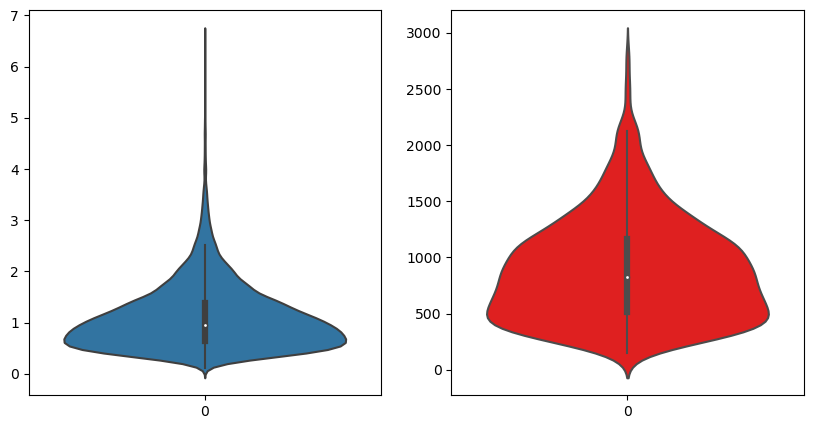

In [95]:
fig, ax = plt.subplots(1,2, figsize = (10,5))

sns.violinplot(df["co"][~df["station_id"].isin(["BL-03", "PT-03"])], ax = ax[0])
sns.violinplot(list(df["co"][df["station_id"].isin(["BL-03", "PT-03"])]), ax = ax[1], color = "red")
plt.show()

In [96]:
# every row of BL-03 and PT-03 is ~1000x too high (different unit) -> bring to mg/m3 like the other stations
df["co"][df["station_id"].isin(["BL-03", "PT-03"])] = df["co"][df["station_id"].isin(["BL-03", "PT-03"])] / 1000

In [97]:
#checking
df.groupby("station_id")["co"].median().describe()

count    24.000000
mean      0.991783
std       0.361375
min       0.480000
25%       0.775000
50%       0.865000
75%       1.360000
max       1.570000
Name: co, dtype: float64

#### Target errors: PM2.5 higher than PM10 (check)

In [98]:
# PM2.5 is a part of PM10, so PM2.5 > PM10 is not possible
df[(df["pm2_5_ugm3"] / df["pm10"]) > 1][["date", "station_id", "pm10", "pm2_5_ugm3"]]

,date,station_id,pm10,pm2_5_ugm3
574,2024-11-28,DL-01,429.9,1963.9
3611,2025-04-16,LK-03,106.5,478.7
6112,2025-08-09,DL-02,33.1,167.4
7889,2025-10-30,MB-03,72.9,428.1
8268,2025-11-15,HY-03,43.7,244.8
9766,2026-01-22,PT-01,404.2,2189.4
11542,2026-04-14,HY-03,86.5,409.9
11786,2026-04-26,DL-02,113.4,392.4
12990,2026-06-19,LK-03,44.5,178.6
14054,2026-08-11,CH-02,48.3,262.7


In [99]:
list(df[(df["pm2_5_ugm3"] / df["pm10"]) > 1][["date", "station_id", "pm10", "pm2_5_ugm3"]].index)

[574, 3611, 6112, 7889, 8268, 9766, 11542, 11786, 12990, 14054, 14105]

In [100]:
# target cannot be fixed or imputed, so the rows go
df = df[~df.index.isin(list(df[(df["pm2_5_ugm3"] / df["pm10"]) > 1][["date", "station_id", "pm10", "pm2_5_ugm3"]].index))]
df = df.reset_index(drop = True)

#### NO2 errors: NO2 far above NOx (check)

In [101]:
# NOx includes NO2, so NO2 should be close to NOx (median ratio ~1)
df[((df["no2"] / df["nox"]) > 5) & (df["no2"] > 100)][["date", "station_id", "no", "no2", "nox"]]

,date,station_id,no,no2,nox
379,2024-11-19,KL-01,24.1,329.3,35.8
3242,2025-03-29,KL-01,21.2,290.7,30.1
3598,2025-04-15,MB-03,59.7,827.8,93.7
3843,2025-04-27,BL-03,13.1,256.9,26.3
8904,2025-12-14,KL-02,64.2,717.2,86.8
9160,2025-12-26,PT-02,43.6,685.1,72.7
9607,2026-01-15,KL-02,80.9,598.8,96.8
11734,2026-04-24,DL-02,38.0,412.0,52.3
14860,2026-09-21,CH-02,57.7,658.6,81.4


In [102]:
df["no2"].isna().sum()

423

In [103]:
#NO2 errors: make them NaN (to impute later)
# only the NO2 reading is wrong, the rest of the row is fine -> keep the row
df.iloc[df[((df["no2"] / df["nox"]) > 5) & (df["no2"] > 100)][["date", "station_id", "no", "no2", "nox"]].index]["no2"] = np.nan

In [104]:
df["no2"].iloc[list(df[((df["no2"] / df["nox"]) > 5) & (df["no2"] > 100)][["date", "station_id", "no", "no2", "nox"]].index)] = np.nan

In [105]:
df["no2"].isna().sum()

432

#### Z-score table again (after the fixes)

In [106]:
# remaining extremes (no, nox, so2, pm10, rainfall) agree with other pollutants/stations -> real, kept
num_cols = [c for c in df.select_dtypes(include=["float64", "int64"]).columns if c not in ["festival_flag", "holiday_flag"]]

pd.DataFrame({c: z_score(c).abs().nlargest(5).values for c in num_cols})

,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,relative_humidity_pct,wind_speed_ms,wind_direction_deg,pressure_hpa,rainfall_mm,solar_radiation_wm2,boundary_layer_height_m,visibility_km,upwind_fire_count,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
0,2.278743,2.703399,3.055827,3.142996,2.668089,3.230837,3.027409,5.186013,1.925027,2.570689,18.949455,2.183406,5.817078,3.314753,6.58412,10.778301,21.616648,7.911071,16.013010,6.570356,12.017276,8.819019,3.063086,7.530863,9.100623,9.948191
1,2.278743,2.703399,3.055827,3.142996,2.668089,3.212541,2.958713,5.186013,1.925027,2.536522,18.808396,2.171613,4.957102,3.314753,6.58412,10.272232,12.628125,7.730709,9.782780,5.657670,9.941108,7.694332,2.990305,7.073948,7.561554,8.803433
2,2.278743,2.703399,3.055827,3.142996,2.668089,3.194245,2.821323,5.186013,1.925027,2.530827,16.799987,2.112647,4.703227,3.314753,6.58412,9.905112,11.336336,7.198010,8.779801,5.619641,9.826221,7.148055,2.894779,6.256529,7.535605,8.636368
3,2.278743,2.703399,3.055827,3.142996,2.668089,3.157652,2.752627,5.186013,1.925027,2.527980,15.866312,2.100854,4.664345,3.314753,6.58412,9.363940,9.832711,7.114121,8.466166,5.378793,9.752365,6.328641,2.808351,6.038551,6.878785,8.505622
4,2.278743,2.703399,3.055827,3.142996,2.668089,3.121060,2.752627,5.186013,1.925027,2.525132,14.173607,1.982922,4.662058,3.219438,6.58412,8.871034,9.670718,6.824702,8.338752,5.334427,9.128694,6.248306,2.749216,5.971481,6.700389,7.883850


### Missing Values Analysis

In [107]:
#Missing Values Percentage
df.isna().mean().sort_values(ascending=False) * 100

benzene                        32.075472
toluene                        32.018296
solar_radiation_wm2            26.669208
nh3                            26.637444
ozone                          12.534146
no                              6.460835
nox                             6.441776
visibility_km                   5.870021
pressure_hpa                    2.966775
wind_direction_deg              2.941363
co                              2.896893
upwind_fire_count               2.788895
no2                             2.744425
so2                             2.604663
pm10                            2.433136
rainfall_mm                     2.128200
wind_speed_ms                   2.026555
relative_humidity_pct           1.454800
temperature_c                   0.844927
dust_alert                      0.000000
date                            0.000000
boundary_layer_height_m         0.000000
holiday_flag                    0.000000
festival_flag                   0.000000
station_id      

In [108]:
def missing_values(missing_col, comparison_col):
    df1 = df[df[missing_col].isna()][[comparison_col]].value_counts().sort_index().reset_index()
    df1.columns = [comparison_col, "Blanks"]
    return df1

def not_missing_values(not_missing_col, comparison_col):
    df2 = df[~df[not_missing_col].isna()][[comparison_col]].value_counts().sort_index().reset_index()
    df2.columns = [comparison_col, "Non Blanks"]
    return df2

def merge_blank_non_blank(blank_column, comparison_col):
    return not_missing_values(blank_column, comparison_col).merge(missing_values(blank_column, comparison_col), how = "outer").fillna(0)

In [109]:
merge_blank_non_blank("benzene", "station_id")

,station_id,Non Blanks,Blanks
0,BL-01,669.0,18
1,BL-02,652.0,33
2,CH-01,539.0,22
3,CH-02,545.0,26
4,CH-03,647.0,19
5,DL-01,598.0,24
6,HY-02,655.0,23
7,HY-03,656.0,29
8,KL-01,659.0,27
9,KL-02,579.0,27


In [110]:
merge_blank_non_blank("toluene", "station_id")

,station_id,Non Blanks,Blanks
0,BL-01,668.0,19
1,BL-02,656.0,29
2,CH-01,542.0,19
3,CH-02,551.0,20
4,CH-03,639.0,27
5,DL-01,594.0,28
6,HY-02,649.0,29
7,HY-03,661.0,24
8,KL-01,662.0,24
9,KL-02,574.0,32


In [111]:
merge_blank_non_blank("solar_radiation_wm2", "station_id")

,station_id,Non Blanks,Blanks
0,BL-02,663.0,22
1,BL-03,588.0,10
2,CH-01,548.0,13
3,DL-01,611.0,11
4,DL-02,684.0,17
5,DL-03,634.0,13
6,HY-02,665.0,13
7,HY-03,672.0,13
8,KL-01,672.0,14
9,KL-02,586.0,20


## Visualization

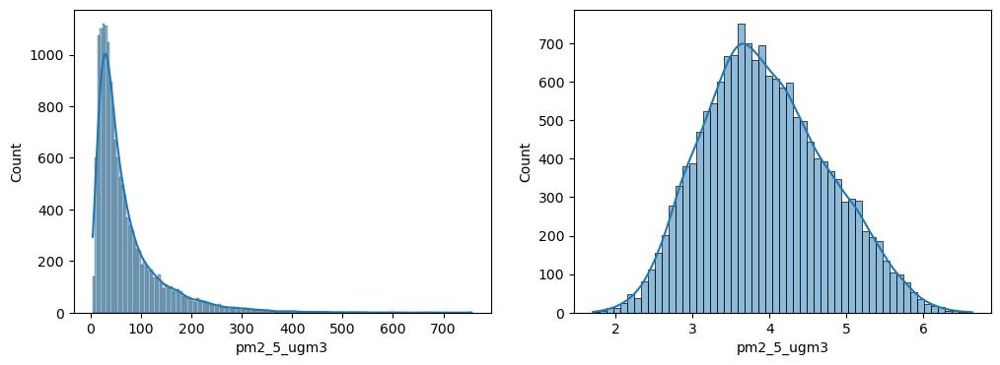

In [112]:
#Target Column
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["pm2_5_ugm3"], kde=True, ax=ax[0])
sns.histplot(np.log1p(df["pm2_5_ugm3"]), kde=True, ax=ax[1])
plt.show()

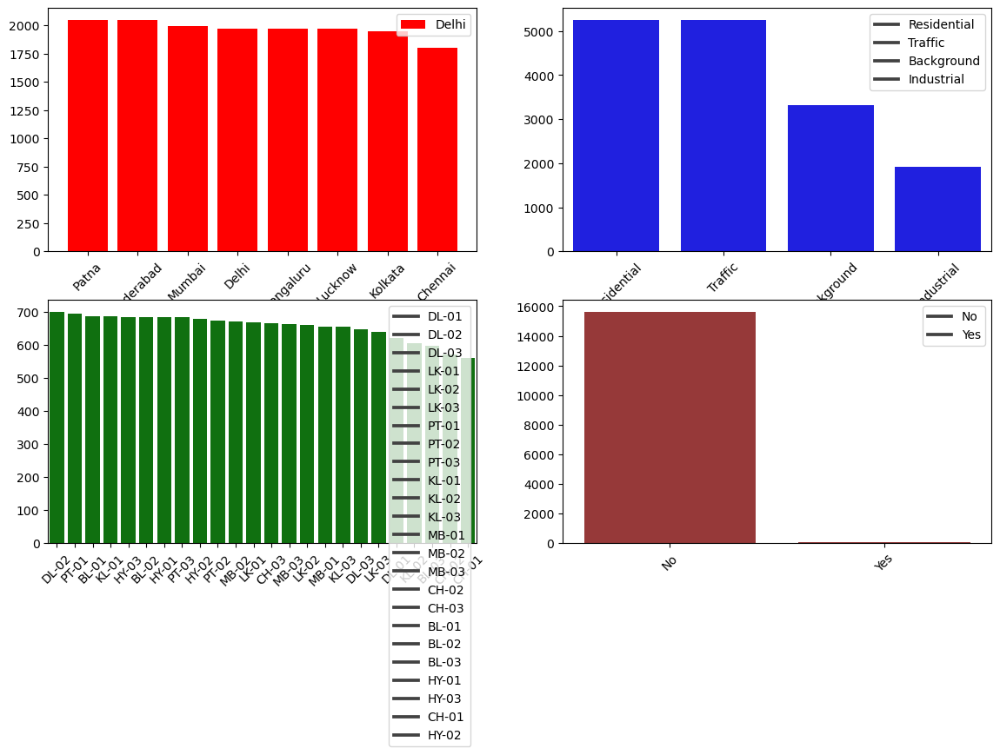

In [113]:
fig, ax = plt.subplots(2,2, figsize = (14,8))

ax[0,0].bar(df["city"].value_counts().index, df["city"].value_counts().values, color = "red")
ax[0,0].tick_params(axis = "x", rotation = 45)

sns.barplot(x = df["station_id"].value_counts().index, y = df["station_id"].value_counts().values, color = "green", ax = ax[1,0])
ax[1,0].tick_params(axis = "x", rotation = 45)

sns.barplot(x = df["station_type"].value_counts().index, y = df["station_type"].value_counts().values, color = "blue", ax = ax[0,1])
ax[0,1].tick_params(axis = "x", rotation = 45)

sns.barplot(x = df["dust_alert"].value_counts().index, y = df["dust_alert"].value_counts().values, color = "brown", ax = ax[1,1])
ax[1,1].tick_params(axis = "x", rotation = 45)

ax[1,1].legend(list(df["dust_alert"].drop_duplicates()))
ax[1,0].legend(list(df["station_id"].drop_duplicates()))
ax[0,0].legend(list(df["city"].drop_duplicates()))
ax[0,1].legend(list(df["station_type"].drop_duplicates()))

plt.show()

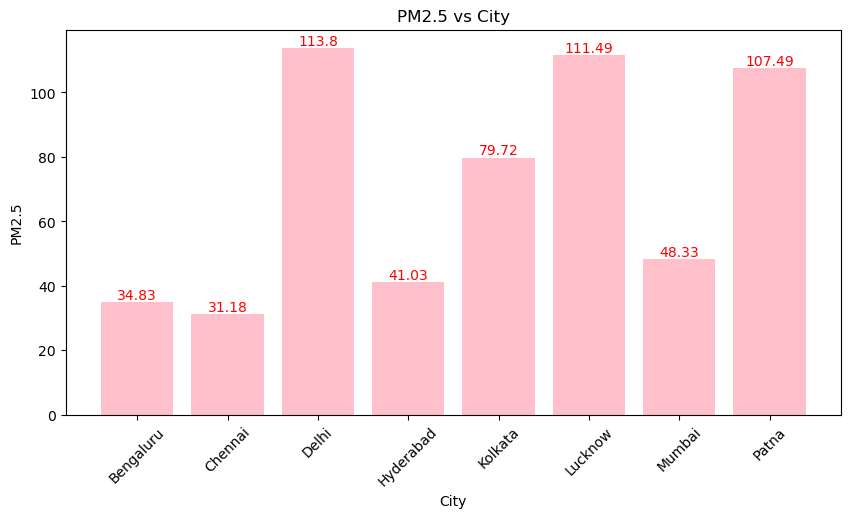

In [114]:
plt.figure(figsize = (10,5))
plt.bar(df.groupby(["city"])["pm2_5_ugm3"].mean().reset_index()["city"], df.groupby(["city"])["pm2_5_ugm3"].mean().reset_index()["pm2_5_ugm3"], color = "pink")
plt.xticks(rotation = 45)
for i,j in enumerate(df.groupby(["city"])["pm2_5_ugm3"].mean().reset_index()["pm2_5_ugm3"]):
    plt.text(i, j, round(j, 2), ha = "center", va = "bottom", fontdict = {"color" : "red"})
plt.xlabel("City")
plt.ylabel("PM2.5")
plt.title("PM2.5 vs City")
plt.show()

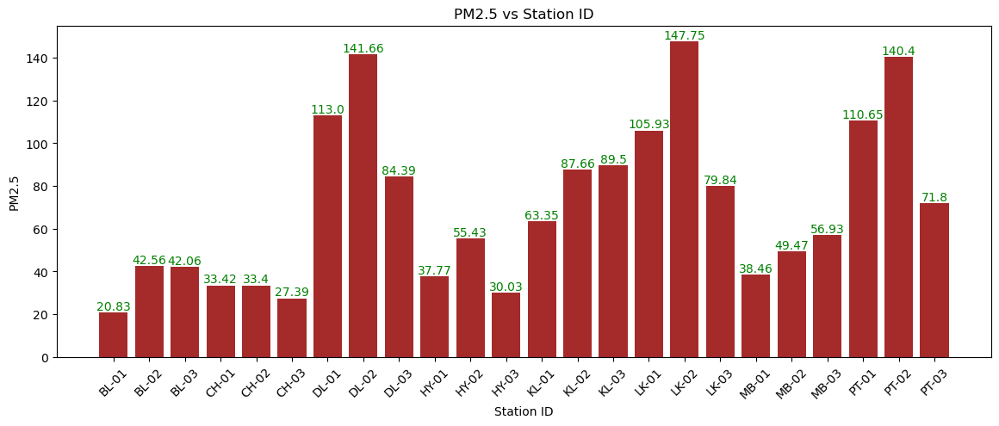

In [115]:
plt.figure(figsize = (14,5))
plt.bar(df.groupby(["station_id"])["pm2_5_ugm3"].mean().reset_index()["station_id"], df.groupby(["station_id"])["pm2_5_ugm3"].mean().reset_index()["pm2_5_ugm3"], color = "brown")
plt.xticks(rotation = 45)
for i,j in enumerate(df.groupby(["station_id"])["pm2_5_ugm3"].mean().reset_index()["pm2_5_ugm3"]):
    plt.text(i, j, round(j, 2), ha = "center", va = "bottom", fontdict = {"color" : "green"})
plt.xlabel("Station ID")
plt.ylabel("PM2.5")
plt.title("PM2.5 vs Station ID")
plt.show()

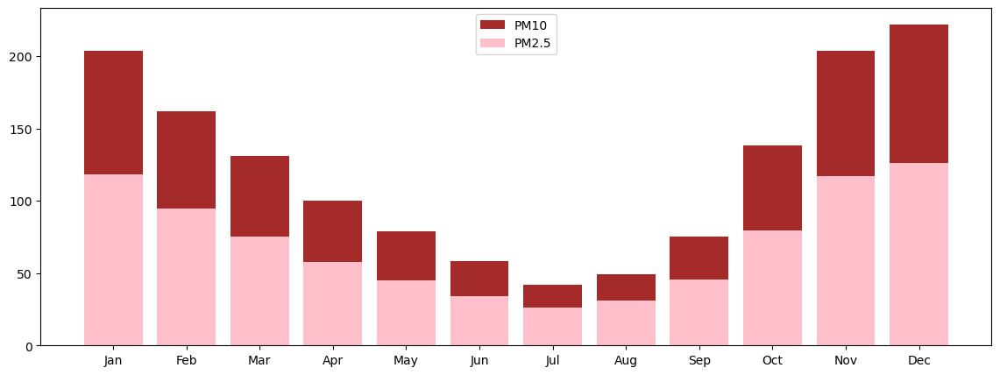

In [116]:
plt.figure(figsize = (14,5))
plt.bar(df.groupby(df["date"].dt.month)["pm10"].mean().reset_index()["date"], df.groupby(df["date"].dt.month)["pm10"].mean().reset_index()["pm10"], label = "PM10", color = "brown")
plt.bar(df.groupby(df["date"].dt.month)["pm2_5_ugm3"].mean().reset_index()["date"], df.groupby(df["date"].dt.month)["pm2_5_ugm3"].mean().reset_index()["pm2_5_ugm3"], label = "PM2.5", color = "pink")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.legend(["PM10", "PM2.5"])
plt.show()

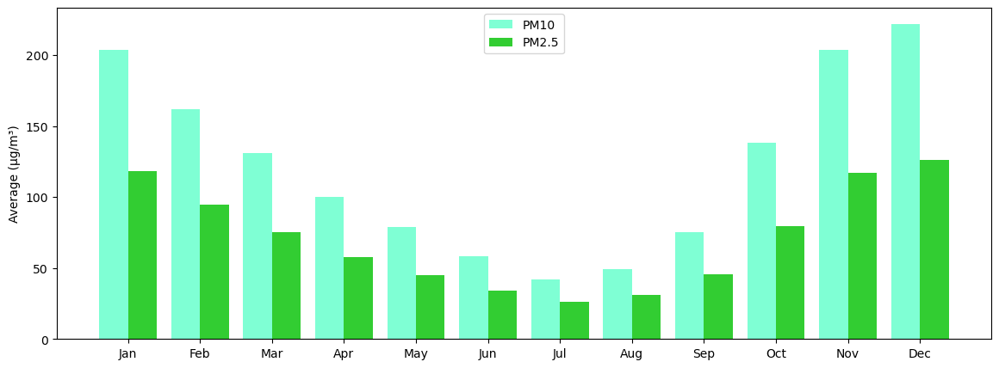

In [117]:
monthly = df.groupby(df["date"].dt.month)[["pm10", "pm2_5_ugm3"]].mean()

plt.figure(figsize=(14, 5))
plt.bar(monthly.index - 0.2, monthly["pm10"], width=0.4, color="aquamarine", label="PM10")
plt.bar(monthly.index + 0.2, monthly["pm2_5_ugm3"], width=0.4, color="limegreen", label="PM2.5")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.ylabel("Average (µg/m³)")
plt.legend()
plt.show()

In [118]:
df

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,relative_humidity_pct,wind_speed_ms,wind_direction_deg,pressure_hpa,rainfall_mm,solar_radiation_wm2,boundary_layer_height_m,visibility_km,upwind_fire_count,festival_flag,holiday_flag,dust_alert,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
0,2024-11-01,DL-01,Delhi,Residential,212.0,8848.0,241.0,57,19.5,15.5,54.0,1.2,301.0,992.1,0.0,123.0,554.0,NaN,1581.0,1,1,No,411.5,31.4,35.6,44.6,43.4,5.7,0.90000,36.4,2.65,5.12,220.9
1,2024-11-01,DL-02,Delhi,Traffic,211.0,9231.0,58.0,45,5.2,15.9,54.0,1.6,328.0,992.8,0.0,114.0,528.0,4.1,1581.0,1,1,No,402.5,33.4,71.1,62.8,27.1,5.9,1.62000,35.2,NaN,NaN,250.6
2,2024-11-01,DL-03,Delhi,Background,220.0,14732.0,2647.0,13,20.2,15.4,53.0,1.2,318.0,991.5,0.0,134.0,491.0,4.9,1581.0,1,1,No,283.6,17.5,25.2,29.0,28.0,1.9,0.56000,50.7,NaN,NaN,177.2
3,2024-11-01,LK-01,Lucknow,Residential,126.0,2206.0,172.0,28,15.0,18.8,56.0,0.8,312.0,1000.3,0.0,112.0,651.0,NaN,1581.0,1,1,No,594.4,31.2,42.7,47.5,69.2,6.4,1.65000,33.3,1.59,4.80,388.1
4,2024-11-01,LK-02,Lucknow,Traffic,124.0,2678.0,45.0,30,8.0,19.2,56.0,1.1,322.0,999.5,0.0,102.0,654.0,2.5,1581.0,1,1,No,NaN,87.9,52.2,96.1,NaN,14.7,2.82000,41.6,7.05,20.51,392.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15736,2026-10-31,BL-02,Bengaluru,Traffic,916.0,3245.0,58.0,37,8.7,19.7,83.0,3.1,107.0,910.7,10.8,87.0,702.0,10.9,912.0,0,0,No,44.3,57.0,60.6,79.4,11.1,4.4,1.94000,10.6,4.63,7.38,42.2
15737,2026-10-31,BL-03,Bengaluru,Industrial,920.0,4462.0,334.0,94,8.5,20.7,84.0,3.4,125.0,910.2,10.5,84.0,713.0,9.8,912.0,0,0,No,57.7,25.0,58.4,50.0,NaN,12.0,1.01358,NaN,NaN,NaN,43.2
15738,2026-10-31,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,20.3,62.0,2.4,150.0,955.1,0.0,NaN,754.0,10.5,912.0,0,0,No,141.5,11.5,18.8,19.5,14.5,3.3,0.78000,26.5,NaN,NaN,72.2
15739,2026-10-31,HY-02,Hyderabad,Traffic,493.0,17628.0,35.0,37,4.9,20.7,58.0,1.5,115.0,955.6,0.0,110.0,743.0,8.5,912.0,0,0,No,130.7,56.3,60.8,NaN,NaN,5.7,2.09000,36.1,8.73,26.44,79.8


<Axes: xlabel='population_density_per_km2', ylabel='Proportion'>

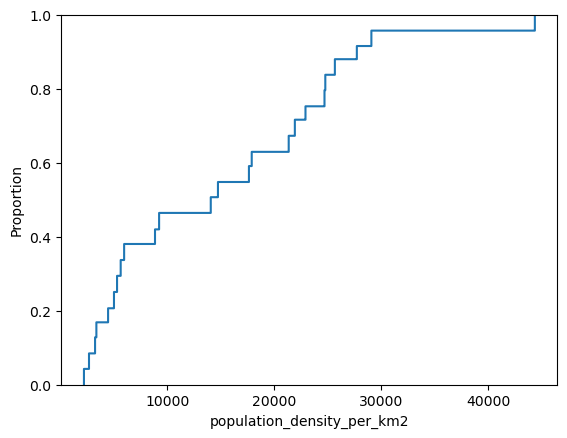

In [119]:
sns.ecdfplot(df["population_density_per_km2"])

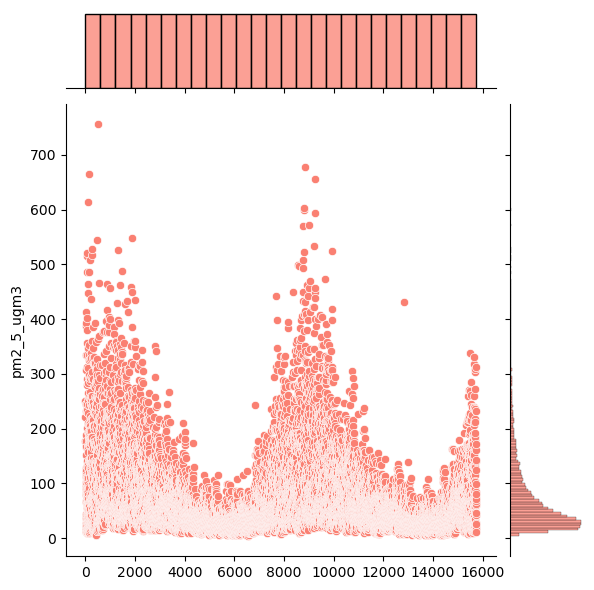

In [120]:
sns.jointplot(df["pm2_5_ugm3"], color = "salmon")

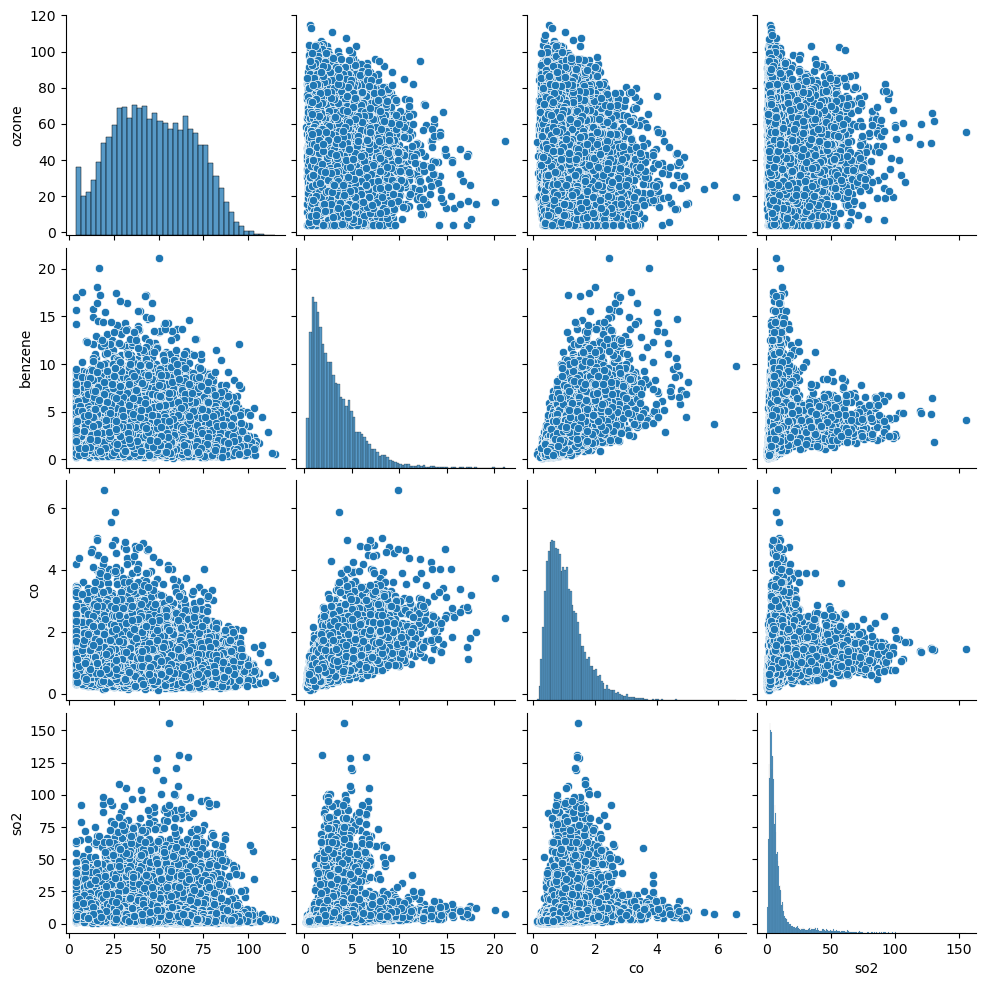

In [121]:
sns.pairplot(df[["ozone", "benzene", "co", "so2"]])

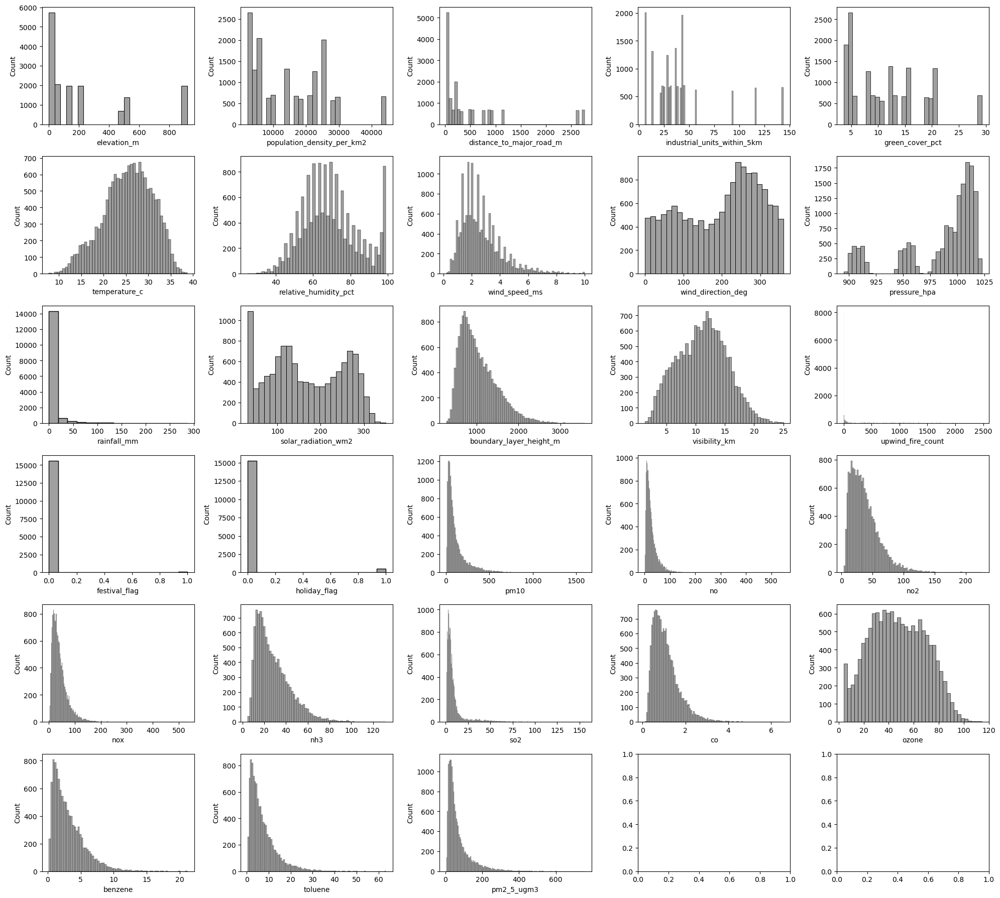

In [122]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns

fig, ax = plt.subplots(6, 5, figsize=(20, 18))
for a, c in zip(ax.flatten(), num_cols):
    sns.histplot(df[c], kde=False, ax=a, color = "gray")
plt.tight_layout()

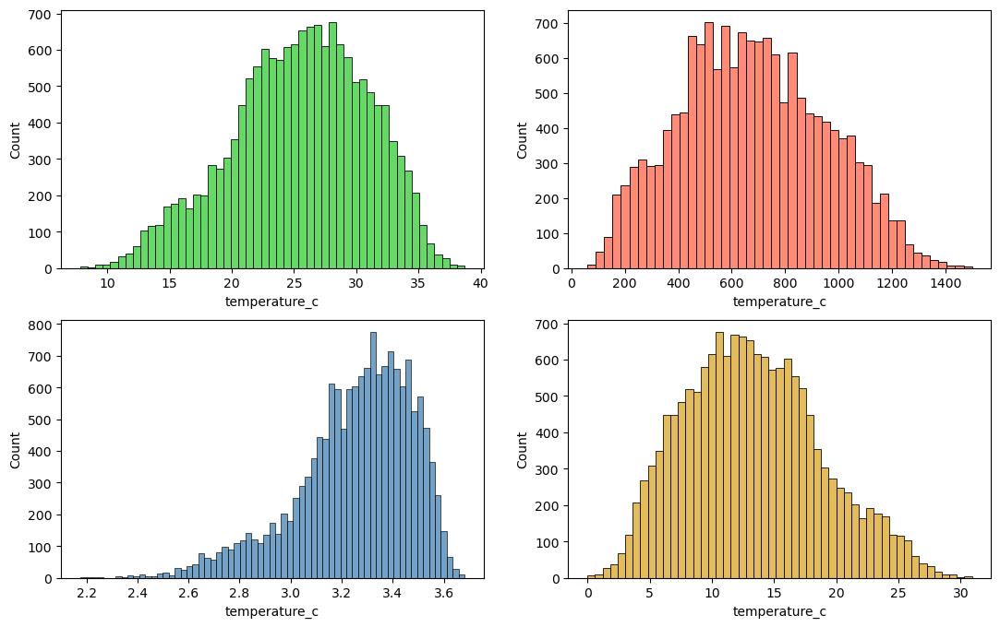

In [123]:
#Effects of transformations on different types of skewed data

fig, ax = plt.subplots(2,2, figsize = (13,8))
sns.histplot(df["temperature_c"], ax = ax[0,0], color = "limegreen")
sns.histplot(df["temperature_c"]**2, ax = ax[0,1], color = "tomato") #takes you to left, as you keep increasing the power
sns.histplot(np.log1p(df["temperature_c"]), ax = ax[1,0], color = "steelblue") #will take you further right, use this for right skewed data
sns.histplot(df["temperature_c"].max() - df["temperature_c"], ax = ax[1,1], color = "goldenrod") #this is mirror image - then you can use log to pull it towards right
#or you can use a fraction power also of the last mirror image example to bring it towards right: (df["temperature_c"].max() - df["temperature_c"]) ** (0.8)
plt.show()

In [124]:
df

,date,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,relative_humidity_pct,wind_speed_ms,wind_direction_deg,pressure_hpa,rainfall_mm,solar_radiation_wm2,boundary_layer_height_m,visibility_km,upwind_fire_count,festival_flag,holiday_flag,dust_alert,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,pm2_5_ugm3
0,2024-11-01,DL-01,Delhi,Residential,212.0,8848.0,241.0,57,19.5,15.5,54.0,1.2,301.0,992.1,0.0,123.0,554.0,NaN,1581.0,1,1,No,411.5,31.4,35.6,44.6,43.4,5.7,0.90000,36.4,2.65,5.12,220.9
1,2024-11-01,DL-02,Delhi,Traffic,211.0,9231.0,58.0,45,5.2,15.9,54.0,1.6,328.0,992.8,0.0,114.0,528.0,4.1,1581.0,1,1,No,402.5,33.4,71.1,62.8,27.1,5.9,1.62000,35.2,NaN,NaN,250.6
2,2024-11-01,DL-03,Delhi,Background,220.0,14732.0,2647.0,13,20.2,15.4,53.0,1.2,318.0,991.5,0.0,134.0,491.0,4.9,1581.0,1,1,No,283.6,17.5,25.2,29.0,28.0,1.9,0.56000,50.7,NaN,NaN,177.2
3,2024-11-01,LK-01,Lucknow,Residential,126.0,2206.0,172.0,28,15.0,18.8,56.0,0.8,312.0,1000.3,0.0,112.0,651.0,NaN,1581.0,1,1,No,594.4,31.2,42.7,47.5,69.2,6.4,1.65000,33.3,1.59,4.80,388.1
4,2024-11-01,LK-02,Lucknow,Traffic,124.0,2678.0,45.0,30,8.0,19.2,56.0,1.1,322.0,999.5,0.0,102.0,654.0,2.5,1581.0,1,1,No,NaN,87.9,52.2,96.1,NaN,14.7,2.82000,41.6,7.05,20.51,392.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15736,2026-10-31,BL-02,Bengaluru,Traffic,916.0,3245.0,58.0,37,8.7,19.7,83.0,3.1,107.0,910.7,10.8,87.0,702.0,10.9,912.0,0,0,No,44.3,57.0,60.6,79.4,11.1,4.4,1.94000,10.6,4.63,7.38,42.2
15737,2026-10-31,BL-03,Bengaluru,Industrial,920.0,4462.0,334.0,94,8.5,20.7,84.0,3.4,125.0,910.2,10.5,84.0,713.0,9.8,912.0,0,0,No,57.7,25.0,58.4,50.0,NaN,12.0,1.01358,NaN,NaN,NaN,43.2
15738,2026-10-31,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,20.3,62.0,2.4,150.0,955.1,0.0,NaN,754.0,10.5,912.0,0,0,No,141.5,11.5,18.8,19.5,14.5,3.3,0.78000,26.5,NaN,NaN,72.2
15739,2026-10-31,HY-02,Hyderabad,Traffic,493.0,17628.0,35.0,37,4.9,20.7,58.0,1.5,115.0,955.6,0.0,110.0,743.0,8.5,912.0,0,0,No,130.7,56.3,60.8,NaN,NaN,5.7,2.09000,36.1,8.73,26.44,79.8


#### Plotly

In [125]:
import plotly.express as px

In [126]:
#Boxplot - segregated by cities
px.box(df, x="city", y="pm2_5_ugm3", color="city").show()

In [127]:
#Line chart throughout the months in each city
monthly = df.groupby([df["date"].dt.month.rename("month"), "city"])["pm2_5_ugm3"].mean().reset_index()
px.line(monthly, x="month", y="pm2_5_ugm3", color="city", markers=True).show()

In [128]:
px.scatter(df, x="wind_speed_ms", y="pm10", color="station_type", hover_data=["station_type", "date"], opacity=0.6).show()

In [129]:
pivot = df.pivot_table(index = "city", columns = df["date"].dt.month, values = "pm2_5_ugm3", aggfunc = "mean")
px.imshow(pivot, text_auto = ".0f", color_continuous_scale = "YlOrRd", labels = dict(x = "Month", y = "City", color = "PM2.5")).show()

In [130]:
pivot = df.pivot_table(index = "city", columns = df["date"].dt.year, values = "pm2_5_ugm3", aggfunc = "mean")
px.imshow(pivot, text_auto = ".0f", color_continuous_scale = "Reds", labels = dict(x = "Year", y = "City", color = "PM2.5")).show()

### Splitting the Data

In [131]:
#Make sure you do not take count of a column which has blanks - hence 'station_id'
df_monthly = pd.DataFrame(df.groupby(df["date"].dt.to_period("M"))["station_id"].count()).reset_index()
df_monthly.columns = ["Period", "Count"]

In [132]:
df_monthly["Cumulative Count"] = df_monthly.index.map(lambda i : sum(df_monthly["Count"][:(i+1)]))
df_monthly["Cumulative Count Percentage"] = df_monthly["Cumulative Count"]/df_monthly["Count"].sum()

In [133]:
df[df["date"] >= "2026-06-01"].shape

(3180, 33)

In [134]:
df_monthly[df_monthly["Period"] >= "2026-06"]["Count"].sum()

3180

In [135]:
# Split by whole WEEKS (not random rows, not a time cutoff):
# - random rows would leak: same-day columns like upwind_fire_count are identical across stations,
#   and neighbouring days at one station are near copies, so test scores would look too good
# - a time cutoff would drop Jan-May from test (if we take 80-20), so some seasons would never be tested
# - weekly blocks keep all stations of a day together, and random weeks spread test across all seasons
# - model uses same-day features (no lag/past PM2.5), so this is a regression, not a timeseries forecast

In [136]:
df["week"] = df["date"].dt.year.astype('str') + ' - ' + df["date"].dt.week.astype('str')

In [137]:
weeks = df["week"].unique()
test_weeks = np.random.RandomState(2).choice(weeks, size = int(len(weeks) * 0.2), replace = False)

test = df[df["week"].isin(test_weeks)]
train = df[~df["week"].isin(test_weeks)]

In [138]:
train.shape, test.shape

((12685, 34), (3056, 34))

In [139]:
#their purpose was just to do the train-test split
train.drop("week", axis = 1, inplace = True)
test.drop("week", axis = 1, inplace = True)

In [140]:
X_train = train[train.columns[~train.columns.isin(["pm2_5_ugm3"])]]
y_train = train["pm2_5_ugm3"]
X_test = test[test.columns[~test.columns.isin(["pm2_5_ugm3"])]]
y_test = test["pm2_5_ugm3"]

In [141]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((12685, 32), (12685,), (3056, 32), (3056,))

In [142]:
# Cyclical encoding: angle = 2*pi * (month / 12), i.e. how far through the year we are, turned into a position on a circle
# month / 12      -> fraction of the year done (March = 3/12 = a quarter)
# 2*pi * fraction -> that fraction as an angle (2*pi = one full lap of the circle)
# sin and cos     -> the (height, sideways) position of that point, like a clock hand
# Dec lands next to Jan and Jul sits opposite Jan; day_of_year works the same way with / 365

In [143]:
# Month and day of year as a circle (sin + cos) so Dec sits next to Jan; sin alone repeats values, the pair is unique for each point in the year
# raw 'date' is dropped because the model cannot read a date directly

for i in [X_train, X_test]:
    i["month_sin"] = np.sin(2 * np.pi * i["date"].dt.month / 12)
    i["month_cos"] = np.cos(2 * np.pi * i["date"].dt.month / 12)
    i["doy_sin"] = np.sin(2 * np.pi * i["date"].dt.dayofyear / 365)
    i["doy_cos"] = np.cos(2 * np.pi * i["date"].dt.dayofyear / 365)

X_train = X_train.drop("date", axis=1)
X_test = X_test.drop("date", axis=1)

In [144]:
X_train

,station_id,city,station_type,elevation_m,population_density_per_km2,distance_to_major_road_m,industrial_units_within_5km,green_cover_pct,temperature_c,relative_humidity_pct,wind_speed_ms,wind_direction_deg,pressure_hpa,rainfall_mm,solar_radiation_wm2,boundary_layer_height_m,visibility_km,upwind_fire_count,festival_flag,holiday_flag,dust_alert,pm10,no,no2,nox,nh3,so2,co,ozone,benzene,toluene,month_sin,month_cos,doy_sin,doy_cos
66,DL-01,Delhi,Residential,212.0,8848.0,241.0,57,19.5,14.7,50.0,0.9,314.0,989.3,0.0,131.0,598.0,3.5,1735.0,0,0,No,458.8,44.6,67.5,72.4,40.8,6.1,1.71000,44.7,4.16,7.11,-0.500000,0.866025,-0.821477,0.570242
67,DL-02,Delhi,Traffic,211.0,9231.0,58.0,45,5.2,14.7,52.0,0.9,330.0,NaN,0.0,130.0,657.0,3.0,1735.0,0,0,No,555.4,67.0,NaN,108.0,30.4,10.7,2.00000,26.8,NaN,NaN,-0.500000,0.866025,-0.821477,0.570242
68,DL-03,Delhi,Background,220.0,14732.0,2647.0,13,20.2,15.2,46.0,0.8,330.0,988.0,0.0,127.0,562.0,3.6,1735.0,0,0,No,407.8,9.5,26.6,22.1,35.1,3.8,0.73000,38.7,NaN,NaN,-0.500000,0.866025,-0.821477,0.570242
69,LK-01,Lucknow,Residential,126.0,2206.0,172.0,28,15.0,15.8,48.0,1.0,312.0,998.9,0.0,122.0,535.0,3.9,1735.0,0,0,No,663.2,27.9,59.5,54.0,25.6,11.1,1.38000,38.4,1.79,3.73,-0.500000,0.866025,-0.821477,0.570242
70,LK-02,Lucknow,Traffic,124.0,2678.0,45.0,30,8.0,16.7,53.0,1.9,298.0,999.6,0.0,117.0,562.0,NaN,1735.0,0,0,No,1178.4,45.6,88.1,84.2,NaN,11.8,1.90000,38.4,7.82,10.93,-0.500000,0.866025,-0.821477,0.570242
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15736,BL-02,Bengaluru,Traffic,916.0,3245.0,58.0,37,8.7,19.7,83.0,3.1,107.0,910.7,10.8,87.0,702.0,10.9,912.0,0,0,No,44.3,57.0,60.6,79.4,11.1,4.4,1.94000,10.6,4.63,7.38,-0.866025,0.500000,-0.867456,0.497513
15737,BL-03,Bengaluru,Industrial,920.0,4462.0,334.0,94,8.5,20.7,84.0,3.4,125.0,910.2,10.5,84.0,713.0,9.8,912.0,0,0,No,57.7,25.0,58.4,50.0,NaN,12.0,1.01358,NaN,NaN,NaN,-0.866025,0.500000,-0.867456,0.497513
15738,HY-01,Hyderabad,Residential,506.0,21346.0,204.0,39,12.5,20.3,62.0,2.4,150.0,955.1,0.0,NaN,754.0,10.5,912.0,0,0,No,141.5,11.5,18.8,19.5,14.5,3.3,0.78000,26.5,NaN,NaN,-0.866025,0.500000,-0.867456,0.497513
15739,HY-02,Hyderabad,Traffic,493.0,17628.0,35.0,37,4.9,20.7,58.0,1.5,115.0,955.6,0.0,110.0,743.0,8.5,912.0,0,0,No,130.7,56.3,60.8,NaN,NaN,5.7,2.09000,36.1,8.73,26.44,-0.866025,0.500000,-0.867456,0.497513


### Categorical Variables

In [145]:
# The station_id perfectly captures the city (first 2 alphabets) and the station_type (last 2 alphabets) 
# - hence we can remove the other two columns as they are redundant (correlated as well in a way)

In [146]:
X_train = X_train.drop(["station_type", "city"], axis = 1)
X_test = X_test.drop(["station_type", "city"], axis = 1)

In [147]:
pd.get_dummies(X_train["station_id"], prefix = "station_id", drop_first = True)

,station_id_BL-02,station_id_BL-03,station_id_CH-01,station_id_CH-02,station_id_CH-03,station_id_DL-01,station_id_DL-02,station_id_DL-03,station_id_HY-01,station_id_HY-02,station_id_HY-03,station_id_KL-01,station_id_KL-02,station_id_KL-03,station_id_LK-01,station_id_LK-02,station_id_LK-03,station_id_MB-01,station_id_MB-02,station_id_MB-03,station_id_PT-01,station_id_PT-02,station_id_PT-03
66,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
67,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
68,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
69,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
70,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15736,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15737,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15738,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15739,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [148]:
#got dummies for station_id - Ridge and Lasso will take care of overfitting, multicollinearity a bit
X_train = pd.get_dummies(X_train, columns = ["station_id"], prefix = "station_id_", drop_first = True)
X_test = pd.get_dummies(X_test, columns = ["station_id"], prefix = "station_id_", drop_first = True)

In [149]:
#Binary Column (Yes/No)
X_train["dust_alert"] = X_train["dust_alert"].map({"Yes" : 1, "No" : 0})
X_test["dust_alert"] = X_test["dust_alert"].map({"Yes" : 1, "No" : 0})

### Imputation - Filling the Blanks 

In [150]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [151]:
imputer = IterativeImputer(max_iter = 10, min_value = 0, random_state = 10)

In [152]:
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns = X_test.columns, index = X_test.index)

In [153]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((12685, 55), (3056, 55), (12685,), (3056,))

### Multicolinearity

<Axes: >

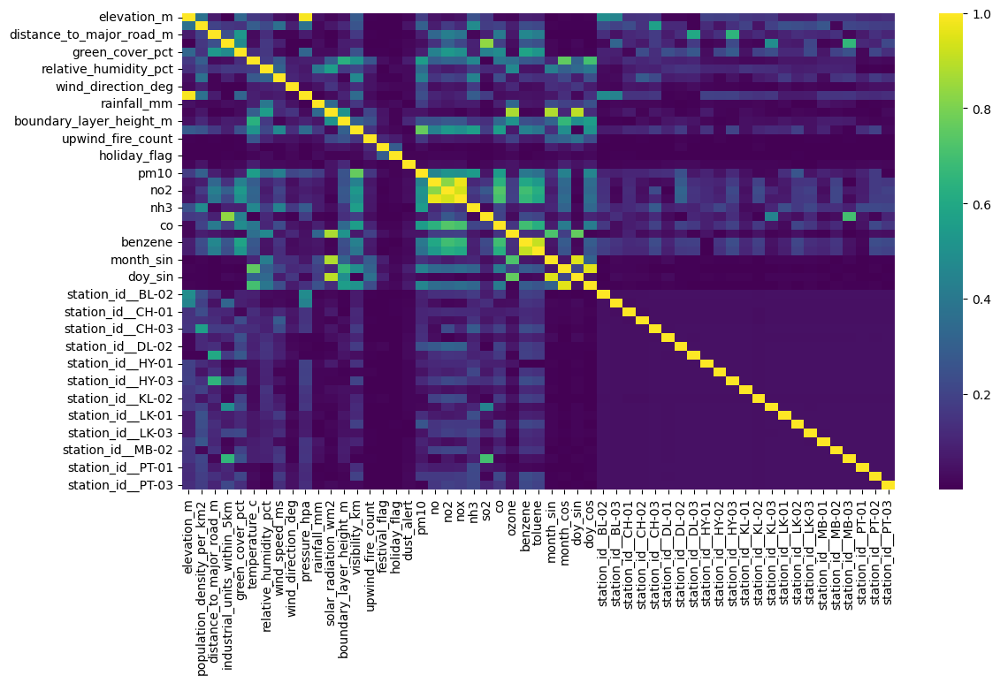

In [154]:
plt.figure(figsize = (13,7))
sns.heatmap(X_train.corr().abs(), cmap = "viridis")

In [155]:
corr = X_train[X_train.columns[~X_train.columns.str.startswith("station_id")]].corr().abs()

In [156]:
corr = corr[corr[corr != 1] > 0.8].stack().sort_values(ascending=False).reset_index()
corr.columns = ["index", "column", "correlation"]

In [157]:
corr.drop_duplicates(subset = ["correlation"])

,index,column,correlation
0,elevation_m,pressure_hpa,0.989150
2,no,nox,0.970478
4,month_cos,doy_cos,0.956168
6,month_sin,doy_sin,0.952723
8,no2,nox,0.934624
10,benzene,toluene,0.913649
12,solar_radiation_wm2,doy_sin,0.901482
14,solar_radiation_wm2,month_sin,0.881958
16,ozone,solar_radiation_wm2,0.871349
18,industrial_units_within_5km,so2,0.834923


#### VIF

In [158]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [159]:
X_vif = add_constant(X_train.loc[:, ~X_train.columns.str.startswith("station_id_")])

In [160]:
#Checking if the station_id dummies are gone or not
X_vif.columns

Index(['const', 'elevation_m', 'population_density_per_km2',
       'distance_to_major_road_m', 'industrial_units_within_5km',
       'green_cover_pct', 'temperature_c', 'relative_humidity_pct',
       'wind_speed_ms', 'wind_direction_deg', 'pressure_hpa', 'rainfall_mm',
       'solar_radiation_wm2', 'boundary_layer_height_m', 'visibility_km',
       'upwind_fire_count', 'festival_flag', 'holiday_flag', 'dust_alert',
       'pm10', 'no', 'no2', 'nox', 'nh3', 'so2', 'co', 'ozone', 'benzene',
       'toluene', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos'],
      dtype='object')

In [161]:
df_vif = pd.DataFrame(zip(X_vif.columns, [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]), columns = ["Columns", "VIF"])

In [162]:
def vif_drop_and_check(cols):
    X_vif_temp = X_vif.drop(cols, axis = 1)
    df_vif_temp = pd.DataFrame(zip(X_vif_temp.columns, [variance_inflation_factor(X_vif_temp.values, i) for i in range(X_vif_temp.shape[1])]), columns = ["Columns", "VIF"])
    return df_vif_temp

In [163]:
vif_drop_and_check(["no"])

,Columns,VIF
0,const,228902.260798
1,elevation_m,276.415018
2,population_density_per_km2,3.529744
3,distance_to_major_road_m,1.980746
4,industrial_units_within_5km,4.783295
5,green_cover_pct,3.587514
6,temperature_c,5.310613
7,relative_humidity_pct,3.101768
8,wind_speed_ms,1.524505
9,wind_direction_deg,1.227595


In [164]:
vif_drop_and_check(["no2"])

,Columns,VIF
0,const,228846.132140
1,elevation_m,276.365082
2,population_density_per_km2,3.525674
3,distance_to_major_road_m,1.981727
4,industrial_units_within_5km,4.771987
5,green_cover_pct,3.584156
6,temperature_c,5.309631
7,relative_humidity_pct,3.101593
8,wind_speed_ms,1.523503
9,wind_direction_deg,1.227664


In [165]:
vif_drop_and_check(["nox"])

,Columns,VIF
0,const,228872.800455
1,elevation_m,276.378417
2,population_density_per_km2,3.528496
3,distance_to_major_road_m,1.980951
4,industrial_units_within_5km,4.782458
5,green_cover_pct,3.588130
6,temperature_c,5.310289
7,relative_humidity_pct,3.101784
8,wind_speed_ms,1.524084
9,wind_direction_deg,1.227605


In [166]:
X_vif.drop("nox", axis = 1, inplace = True)

In [167]:
df_vif = pd.DataFrame(zip(X_vif.columns, [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]), columns = ["Columns", "VIF"])

In [168]:
df_vif

,Columns,VIF
0,const,228872.800455
1,elevation_m,276.378417
2,population_density_per_km2,3.528496
3,distance_to_major_road_m,1.980951
4,industrial_units_within_5km,4.782458
5,green_cover_pct,3.588130
6,temperature_c,5.310289
7,relative_humidity_pct,3.101784
8,wind_speed_ms,1.524084
9,wind_direction_deg,1.227605


In [169]:
vif_drop_and_check("pressure_hpa")

,Columns,VIF
0,const,443.518206
1,elevation_m,3.225616
2,population_density_per_km2,3.528084
3,distance_to_major_road_m,1.972440
4,industrial_units_within_5km,4.782454
5,green_cover_pct,3.570025
6,temperature_c,5.302164
7,relative_humidity_pct,3.098636
8,wind_speed_ms,1.524083
9,wind_direction_deg,1.225086


In [170]:
vif_drop_and_check("elevation_m")

,Columns,VIF
0,const,2940.228990
1,population_density_per_km2,3.513362
2,distance_to_major_road_m,1.977160
3,industrial_units_within_5km,4.776534
4,green_cover_pct,3.542805
5,temperature_c,5.309880
6,relative_humidity_pct,3.098042
7,wind_speed_ms,1.524083
8,wind_direction_deg,1.225052
9,pressure_hpa,3.261150


In [171]:
#dropping either makes sense but elevation_m is a column whose information can be captured in other columns (I feel - like dummy columns)
X_vif.drop("elevation_m", axis = 1, inplace = True)

In [172]:
df_vif = pd.DataFrame(zip(X_vif.columns, [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]), columns = ["Columns", "VIF"])
df_vif

,Columns,VIF
0,const,2940.228990
1,population_density_per_km2,3.513362
2,distance_to_major_road_m,1.977160
3,industrial_units_within_5km,4.776534
4,green_cover_pct,3.542805
5,temperature_c,5.309880
6,relative_humidity_pct,3.098042
7,wind_speed_ms,1.524083
8,wind_direction_deg,1.225052
9,pressure_hpa,3.261150


In [173]:
vif_drop_and_check("solar_radiation_wm2")

,Columns,VIF
0,const,2706.945531
1,population_density_per_km2,3.285007
2,distance_to_major_road_m,1.918185
3,industrial_units_within_5km,4.757568
4,green_cover_pct,3.525501
5,temperature_c,5.293237
6,relative_humidity_pct,2.388372
7,wind_speed_ms,1.515574
8,wind_direction_deg,1.214586
9,pressure_hpa,3.207567


In [174]:
X_vif.drop("solar_radiation_wm2", axis = 1, inplace = True)

In [175]:
df_vif = pd.DataFrame(zip(X_vif.columns, [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]), columns = ["Columns", "VIF"])
df_vif

,Columns,VIF
0,const,2706.945531
1,population_density_per_km2,3.285007
2,distance_to_major_road_m,1.918185
3,industrial_units_within_5km,4.757568
4,green_cover_pct,3.525501
5,temperature_c,5.293237
6,relative_humidity_pct,2.388372
7,wind_speed_ms,1.515574
8,wind_direction_deg,1.214586
9,pressure_hpa,3.207567


In [176]:
# Dropping month_sin and month_cos (keeping the day-of-year pair)
# month and day-of-year are the same yearly circle at two resolutions, so the pairs are near twins (VIF 44-51, corr ~0.95)
# dropping one sin made the other sin's VIF fall below 10 (same for cos), so the overlap is between the two pairs
# sin and cos are kept/dropped together, since only the pair describes the yearly wave
# day-of-year is kept because it is finer and changes smoothly (month jumps at month ends)

In [177]:
X_vif.drop(["month_sin", "month_cos"], axis = 1, inplace = True)

In [178]:
df_vif = pd.DataFrame(zip(X_vif.columns, [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]), columns = ["Columns", "VIF"])
df_vif

,Columns,VIF
0,const,2706.905733
1,population_density_per_km2,3.284412
2,distance_to_major_road_m,1.918103
3,industrial_units_within_5km,4.757359
4,green_cover_pct,3.525445
5,temperature_c,5.291565
6,relative_humidity_pct,2.385418
7,wind_speed_ms,1.514906
8,wind_direction_deg,1.212032
9,pressure_hpa,3.207524


In [179]:
#making the VIF removals in the original data also (dummies are already there from the get_dummies step)
X_train = X_train.drop(["nox", "elevation_m", "solar_radiation_wm2", "month_sin", "month_cos"], axis = 1)
X_test = X_test.drop(["nox", "elevation_m", "solar_radiation_wm2", "month_sin", "month_cos"], axis = 1)

### Scaling the data

In [180]:
from sklearn.preprocessing import StandardScaler

In [181]:
scaler = StandardScaler()

In [182]:
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns = X_test.columns, index = X_test.index)

# REGRESSION

### Linear Regression (sklearn)

In [183]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm

In [184]:
linear_regression = LinearRegression()

In [185]:
linear_regression.fit(X_train_scaled, y_train)

LinearRegression()

In [186]:
y_pred_linear_regression = linear_regression.predict(X_test_scaled)

In [187]:
result_linear_regression = pd.DataFrame(zip(y_test, y_pred_linear_regression), columns = ["Actual", "Predicted"])

In [188]:
result_linear_regression["Residuals"] = result_linear_regression["Actual"] - result_linear_regression["Predicted"]

In [189]:
result_linear_regression

,Actual,Predicted,Residuals
0,220.9,214.025518,6.874482
1,250.6,210.266728,40.333272
2,177.2,155.268682,21.931318
3,388.1,289.369268,98.730732
4,392.6,251.901982,140.698018
...,...,...,...
3051,26.3,27.214971,-0.914971
3052,35.4,43.025518,-7.625518
3053,65.3,64.288213,1.011787
3054,83.7,85.410283,-1.710283


In [190]:
r_square_linear_regression = linear_regression.score(X_test_scaled, y_test)
r_square_linear_regression

0.9446406733632016

In [191]:
# RMSE, MAE
np.sqrt(mean_squared_error(y_test, y_pred_linear_regression)), mean_absolute_error(y_test, y_pred_linear_regression)

(17.931154822883343, 9.638435125790487)

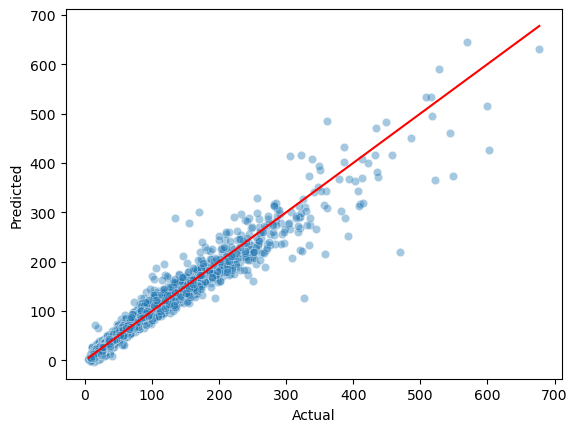

In [192]:
sns.scatterplot(x = result_linear_regression["Actual"], y = result_linear_regression["Predicted"], alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = "red")
plt.show()

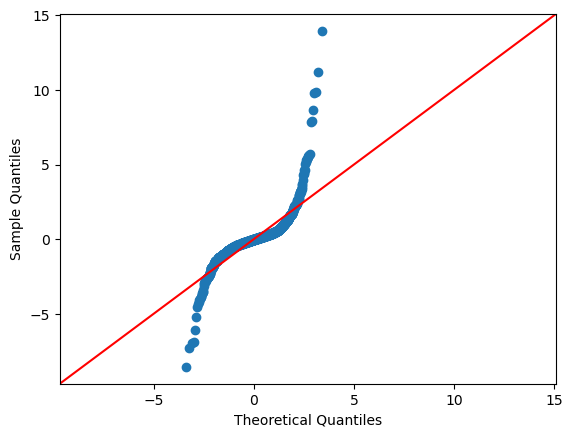

In [193]:
sm.qqplot(result_linear_regression["Residuals"], line="45", fit=True)
plt.show()

### Linear Regression (OLS)

In [194]:
import statsmodels.api as sm

In [195]:
ols = sm.OLS(y_train, sm.add_constant(X_train_scaled)).fit()

In [196]:
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             pm2_5_ugm3   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.956
Method:                 Least Squares   F-statistic:                     5929.
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:31:06   Log-Likelihood:                -51513.
No. Observations:               12685   AIC:                         1.031e+05
Df Residuals:                   12638   BIC:                         1.035e+05
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          69.0811      0.125    553.065      0.000      68.836      69.326
population_density_per_km2     -1.3269      0.605     -2.193      0.028      -2.513      -0.141
distance_to_major_road_m       -0.1101      0.197     -0.560      0.576      -0.496       0.275
industrial_units_within_5km     0.5807      0.260      2.238      0.025       0.072       1.089
green_cover_pct                 4.7360      1.293      3.664      0.000       2.202       7.270
temperature_c                  -2.0851      0.296     -7.037      0.000      -2.666      -1.504
relative_humidity_pct          -1.2445      0.220     -5.647      0.000      -1.676      -0.813
wind_speed_ms                  -0.9761      0.168     -5.816      0.000      -1.305      -0.647
wind_direction_deg              0.5361      0.141      3.815      0.000       0.261       0.812
pressure_hpa                    8.0289      2.126      3.776      0.000       3.861      12.197
rainfall_mm                    -0.1429      0.144     -0.991      0.322      -0.425       0.140
boundary_layer_height_m        -1.1307      0.231     -4.897      0.000      -1.583      -0.678
visibility_km                  -5.8802      0.250    -23.499      0.000      -6.371      -5.390
upwind_fire_count               0.3850      0.145      2.651      0.008       0.100       0.670
festival_flag                   0.6141      0.132      4.666      0.000       0.356       0.872
holiday_flag                   -0.1023      0.131     -0.781      0.435      -0.359       0.154
dust_alert                     -1.7715      0.127    -13.973      0.000      -2.020      -1.523
pm10                           52.3884      0.260    201.170      0.000      51.878      52.899
no                              0.8857      0.245      3.619      0.000       0.406       1.365
no2                             2.1069      0.309      6.822      0.000       1.502       2.712
nh3                             1.4816      0.233      6.372      0.000       1.026       1.937
so2                             0.6696      0.283      2.368      0.018       0.115       1.224
co                              3.8341      0.232     16.556      0.000       3.380       4.288
ozone                           0.2595      0.251      1.033      0.301      -0.233       0.752
benzene                         1.9781      0.366      5.401      0.000       1.260       2.696
toluene                        -0.4971      0.308     -1.612      0.107      -1.102       0.107
doy_sin                         1.1417      0.241      4.728      0.000       0.668       1.615
doy_cos                        -0.6017      0.396     -1.518      0.129      -1.379       0.175
station_id__BL-02               1.8349      0.798      2.299      0.022       0.270       3.399
station_id_

In [197]:
y_pred_linear_regression_ols = ols.predict(sm.add_constant(X_test_scaled))

In [198]:
r_square_linear_regression_ols = r2_score(y_test, y_pred_linear_regression_ols)
r_square_linear_regression_ols

0.9446520651102016

In [199]:
result_linear_regression_ols = pd.DataFrame(zip(y_test, y_pred_linear_regression_ols), columns = ["Actual", "Predicted"])

In [200]:
result_linear_regression_ols["Residuals"] = result_linear_regression_ols["Actual"] - result_linear_regression_ols["Predicted"]

In [201]:
result_linear_regression_ols

,Actual,Predicted,Residuals
0,220.9,213.987800,6.912200
1,250.6,210.322701,40.277299
2,177.2,155.282251,21.917749
3,388.1,289.355040,98.744960
4,392.6,251.925909,140.674091
...,...,...,...
3051,26.3,27.182663,-0.882663
3052,35.4,42.980746,-7.580746
3053,65.3,64.304201,0.995799
3054,83.7,85.451664,-1.751664


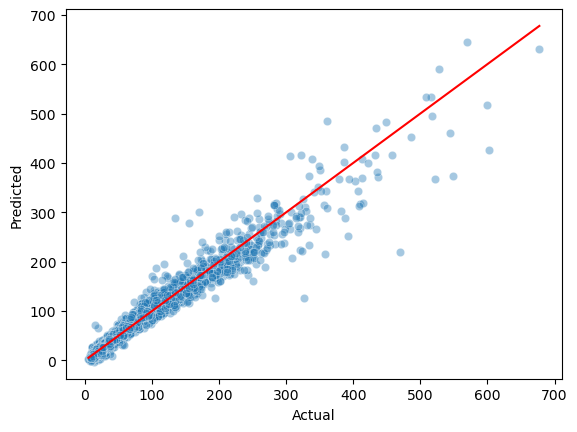

In [202]:
sns.scatterplot(x = result_linear_regression_ols["Actual"], y = result_linear_regression_ols["Predicted"], alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = "red")
plt.show()

### Ridge (L2 Regularization) Regression

In [203]:
from sklearn.linear_model import Ridge

In [204]:
ridge = Ridge(alpha = 1)

In [205]:
ridge.fit(X_train_scaled, y_train)

Ridge(alpha=1)

In [206]:
y_pred_ridge = ridge.predict(X_test_scaled)

In [207]:
result_ridge = pd.DataFrame(zip(y_test, y_pred_ridge), columns=["Actual", "Predicted"])

In [208]:
result_ridge["Residuals"] = result_ridge["Actual"] - result_ridge["Predicted"]

In [209]:
r_square_ridge = r2_score(y_test, y_pred_ridge)
r_square_ridge

0.9446501460977001

In [210]:
np.sqrt(mean_squared_error(y_test, y_pred_ridge)), mean_absolute_error(y_test, y_pred_ridge)

(17.92962062488957, 9.637915653835165)

### Lasso (L1 Regularization) Regression

In [211]:
from sklearn.linear_model import Lasso

In [212]:
lasso = Lasso(alpha = 0.3)

In [213]:
lasso.fit(X_train_scaled, y_train)

Lasso(alpha=0.3)

In [214]:
y_pred_lasso = lasso.predict(X_test_scaled)

In [215]:
result_lasso = pd.DataFrame(zip(y_test, y_pred_lasso), columns=["Actual", "Predicted"])

In [216]:
result_lasso["Residuals"] = result_lasso["Actual"] - result_lasso["Predicted"]

In [217]:
r_square_lasso = r2_score(y_test, y_pred_lasso)
r_square_lasso

0.942366901772038

In [218]:
np.sqrt(mean_squared_error(y_test, y_pred_lasso)), mean_absolute_error(y_test, y_pred_lasso)

(18.29569216364997, 9.722247447818711)

In [219]:
#columns retained by Lasso
X_test_scaled.columns[lasso.coef_ != 0]

Index(['population_density_per_km2', 'temperature_c', 'relative_humidity_pct',
       'wind_speed_ms', 'wind_direction_deg', 'rainfall_mm',
       'boundary_layer_height_m', 'visibility_km', 'festival_flag',
       'dust_alert', 'pm10', 'no', 'no2', 'nh3', 'so2', 'co', 'ozone',
       'benzene', 'doy_sin', 'doy_cos', 'station_id__BL-02',
       'station_id__CH-02', 'station_id__CH-03', 'station_id__DL-01',
       'station_id__DL-02', 'station_id__HY-02', 'station_id__KL-01',
       'station_id__KL-02', 'station_id__KL-03', 'station_id__LK-01',
       'station_id__LK-03', 'station_id__MB-01', 'station_id__MB-02',
       'station_id__PT-01', 'station_id__PT-02', 'station_id__PT-03'],
      dtype='object')

In [220]:
#columns removed by Lasso
X_test_scaled.columns[lasso.coef_ == 0]

Index(['distance_to_major_road_m', 'industrial_units_within_5km',
       'green_cover_pct', 'pressure_hpa', 'upwind_fire_count', 'holiday_flag',
       'toluene', 'station_id__BL-03', 'station_id__CH-01',
       'station_id__DL-03', 'station_id__HY-01', 'station_id__HY-03',
       'station_id__LK-02', 'station_id__MB-03'],
      dtype='object')

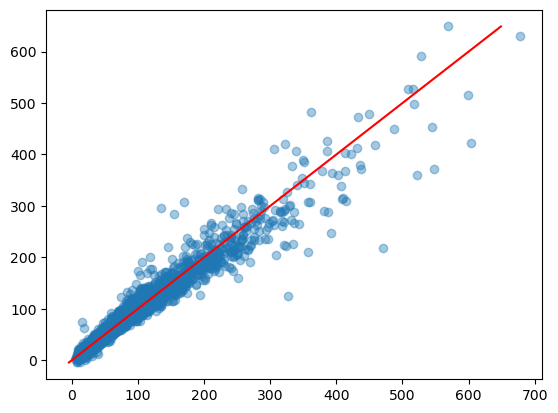

In [221]:
plt.scatter(result_lasso["Actual"], result_lasso["Predicted"], alpha = 0.4)
plt.plot([y_pred_lasso.min(), y_pred_lasso.max()], [y_pred_lasso.min(), y_pred_lasso.max()], color = 'red')
plt.show()

### ElasticNet 

In [222]:
from sklearn.linear_model import ElasticNet

In [223]:
elastic_net = ElasticNet(alpha = 0.3)

In [224]:
elastic_net.fit(X_train_scaled, y_train)

ElasticNet(alpha=0.3)

In [225]:
y_pred_elastic_net = elastic_net.predict(X_test_scaled)
y_pred_elastic_net

array([199.78203422, 202.56825796, 152.36860998, ...,  64.49999521,
        84.46347271,  29.7167796 ])

In [226]:
result_elastic_net = pd.DataFrame(zip(y_test, y_pred_elastic_net), columns=["Actual", "Predicted"])

In [227]:
result_elastic_net["Residuals"] = result_elastic_net["Actual"] - result_elastic_net["Predicted"]

In [228]:
r_square_elastic_net = r2_score(y_test, y_pred_elastic_net)
r_square_elastic_net

0.9251327098323833

In [229]:
np.sqrt(mean_squared_error(y_test, y_pred_elastic_net)), mean_absolute_error(y_test, y_pred_elastic_net)

(20.852537839902705, 11.58711598884405)

In [230]:
#columns retained by ElasticNet
X_test_scaled.columns[elastic_net.coef_ != 0]

Index(['distance_to_major_road_m', 'industrial_units_within_5km',
       'green_cover_pct', 'temperature_c', 'relative_humidity_pct',
       'wind_speed_ms', 'wind_direction_deg', 'pressure_hpa', 'rainfall_mm',
       'boundary_layer_height_m', 'visibility_km', 'upwind_fire_count',
       'festival_flag', 'dust_alert', 'pm10', 'no', 'no2', 'nh3', 'so2', 'co',
       'ozone', 'benzene', 'toluene', 'doy_sin', 'doy_cos',
       'station_id__BL-02', 'station_id__BL-03', 'station_id__CH-01',
       'station_id__CH-02', 'station_id__CH-03', 'station_id__DL-01',
       'station_id__HY-02', 'station_id__HY-03', 'station_id__KL-01',
       'station_id__KL-02', 'station_id__KL-03', 'station_id__LK-01',
       'station_id__LK-02', 'station_id__MB-01', 'station_id__MB-02',
       'station_id__MB-03', 'station_id__PT-01', 'station_id__PT-02',
       'station_id__PT-03'],
      dtype='object')

In [231]:
#columns removed by ElasticNet
X_test_scaled.columns[elastic_net.coef_ == 0]

Index(['population_density_per_km2', 'holiday_flag', 'station_id__DL-02',
       'station_id__DL-03', 'station_id__HY-01', 'station_id__LK-03'],
      dtype='object')

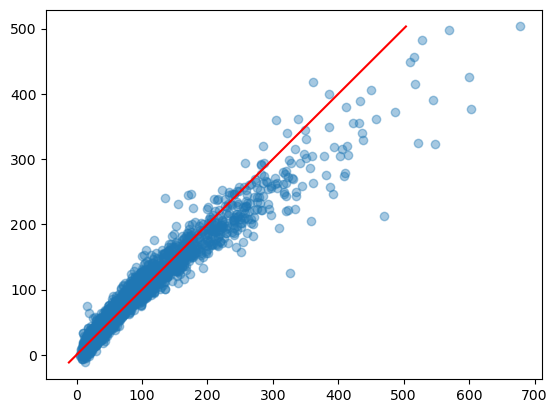

In [232]:
plt.scatter(result_elastic_net["Actual"], result_elastic_net["Predicted"], alpha = 0.4)
plt.plot([y_pred_elastic_net.min(), y_pred_elastic_net.max()], [y_pred_elastic_net.min(), y_pred_elastic_net.max()], color = "red")
plt.show()

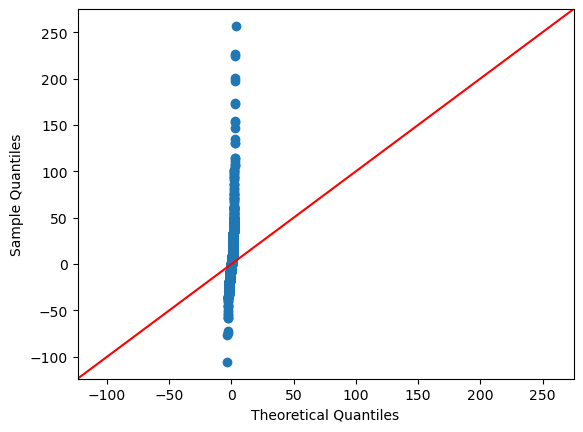

In [233]:
sm.qqplot(result_elastic_net["Residuals"], line = "45")
plt.show()

### Polynomial Regression

In [234]:
from sklearn.preprocessing import PolynomialFeatures

In [235]:
poly = PolynomialFeatures(degree = 2, include_bias = False)

In [236]:
cols = ["pm10", "no2", "co", "wind_speed_ms", "visibility_km", "boundary_layer_height_m"]

In [237]:
X_train_poly = pd.DataFrame(poly.fit_transform(X_train_scaled[cols]), columns = poly.get_feature_names_out(cols), index = X_train_scaled.index)
X_test_poly = pd.DataFrame(poly.transform(X_test_scaled[cols]), columns = poly.get_feature_names_out(cols), index = X_test_scaled.index)

In [238]:
X_train_poly = pd.concat([X_train_scaled.drop(columns = cols), X_train_poly], axis = 1)
X_test_poly = pd.concat([X_test_scaled.drop(columns = cols), X_test_poly], axis = 1)

In [239]:
linear_regression_poly = LinearRegression()

In [240]:
linear_regression_poly.fit(X_train_poly, y_train)

LinearRegression()

In [241]:
y_pred_poly = linear_regression_poly.predict(X_test_poly)
y_pred_poly

array([215.89549884, 223.69202341, 166.6314796 , ...,  63.90941569,
        84.15761776,  29.75878227])

In [242]:
result_poly = pd.DataFrame(zip(y_test, y_pred_poly), columns = ["Actual", "Predicted"])

In [243]:
result_poly["Residuals"] = result_poly["Actual"] - result_poly["Predicted"]

In [244]:
r_square_poly = r2_score(y_test, y_pred_poly)
r_square_poly

0.9610319817886249

In [245]:
np.sqrt(mean_squared_error(y_test, y_pred_poly)), mean_absolute_error(y_test, y_pred_poly)

(15.04412802823628, 8.449983904720954)

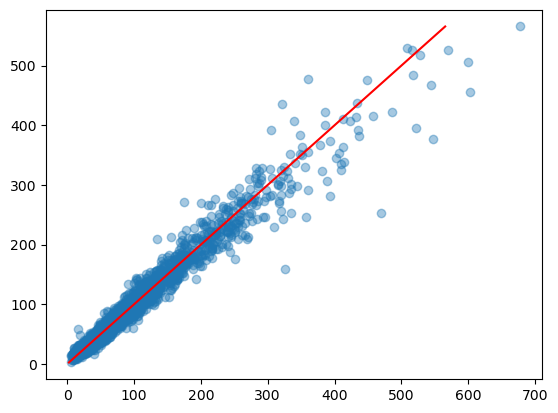

In [246]:
plt.scatter(result_poly["Actual"], result_poly["Predicted"], alpha = 0.4)
plt.plot([y_pred_poly.min(), y_pred_poly.max()], [y_pred_poly.min(), y_pred_poly.max()], color = "red")

### Support Vector Regressor

In [247]:
from sklearn.svm import SVR

In [248]:
svr = SVR(kernel = "rbf", C = 100)

In [249]:
svr.fit(X_train_scaled, y_train)

SVR(C=100)

In [250]:
y_pred_svr = svr.predict(X_test_scaled)

In [251]:
result_svr = pd.DataFrame(zip(y_test, y_pred_svr), columns = ["Actual", "Predicted"])

In [252]:
result_svr["Residuals"] = result_svr["Actual"] - result_svr["Predicted"]

In [253]:
r_square_svr = r2_score(y_test, y_pred_svr)
r_square_svr

0.9087673955113087

In [254]:
np.sqrt(mean_squared_error(y_test, y_pred_svr)), mean_absolute_error(y_test, y_pred_svr)

(23.019076568505263, 9.576347344978911)

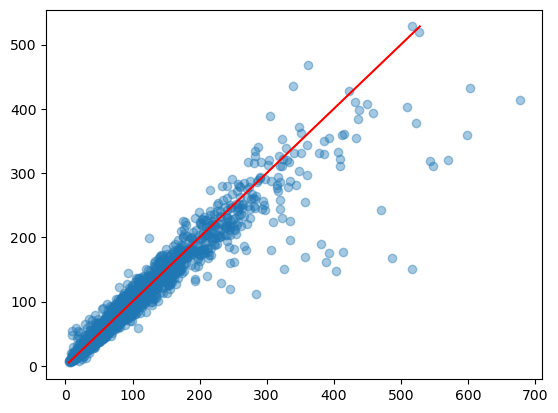

In [255]:
plt.scatter(result_svr["Actual"], result_svr["Predicted"], alpha = 0.4)
plt.plot([y_pred_svr.min(), y_pred_svr.max()], [y_pred_svr.min(), y_pred_svr.max()], color = "red")
plt.show()

## Ensemble Techniques

In [256]:
from sklearn.ensemble import RandomForestRegressor

In [257]:
random_forest = RandomForestRegressor(n_estimators = 200, n_jobs = -1, random_state = 0)

In [258]:
random_forest.fit(X_train_scaled, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)

In [259]:
y_pred_random_forest = random_forest.predict(X_test_scaled)
y_pred_random_forest

array([217.046 , 221.884 , 163.8315, ...,  61.8155,  81.8295,  30.8425])

In [260]:
r_square_random_forest = r2_score(y_test, y_pred_random_forest)
r_square_random_forest

0.9623456818297285

In [261]:
y_pred_random_forest = random_forest.predict(X_test_scaled)
result_random_forest = pd.DataFrame(zip(y_test, y_pred_random_forest), columns = ["Actual", "Predicted"])
result_random_forest["Residuals"] = result_random_forest["Actual"] - result_random_forest["Predicted"]

In [262]:
np.sqrt(mean_squared_error(y_test, y_pred_random_forest)), mean_absolute_error(y_test, y_pred_random_forest)

(14.78836819443651, 8.079704188481676)

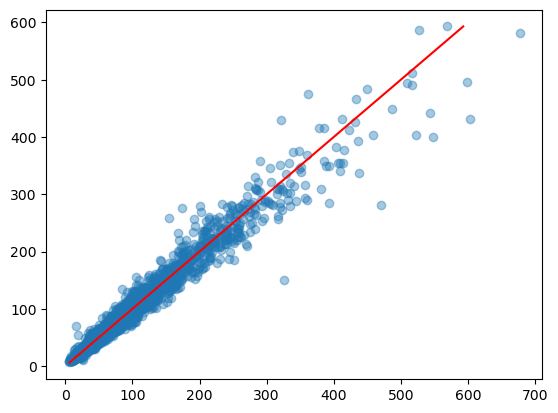

In [263]:
plt.scatter(result_random_forest["Actual"], result_random_forest["Predicted"], alpha = 0.4)
plt.plot([y_pred_random_forest.min(), y_pred_random_forest.max()], [y_pred_random_forest.min(), y_pred_random_forest.max()], color = "red")
plt.show()

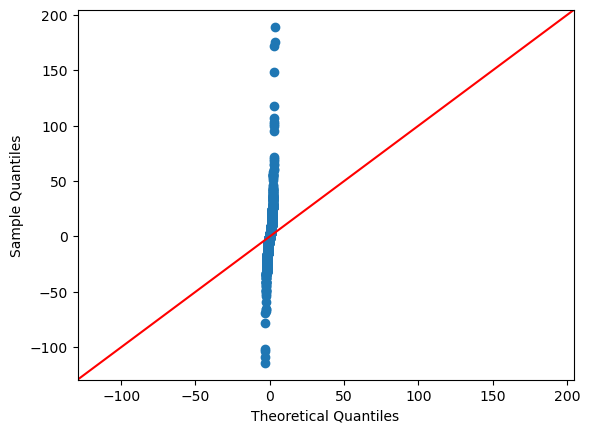

In [264]:
sm.qqplot(result_random_forest["Residuals"], line = "45")
plt.show()

### Bagging (Only use one kind of estimator but multiple of them)

In [265]:
from sklearn.ensemble import BaggingRegressor

In [266]:
from sklearn.tree import DecisionTreeRegressor

In [267]:
bagging_decision_tree = BaggingRegressor(estimator = DecisionTreeRegressor(), n_estimators = 200, n_jobs = -1, random_state = 10)
bagging_decision_tree

BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=200, n_jobs=-1,
                 random_state=10)

In [268]:
bagging_decision_tree.fit(X_train_scaled, y_train)

BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=200, n_jobs=-1,
                 random_state=10)

In [269]:
y_pred_bagging_decision_tree = bagging_decision_tree.predict(X_test_scaled)
y_pred_bagging_decision_tree

array([220.829 , 222.527 , 164.994 , ...,  62.171 ,  82.1275,  30.5145])

In [270]:
r_square_bagging_decision_tree = r2_score(y_test, y_pred_bagging_decision_tree)
r_square_bagging_decision_tree

0.9618771035373324

In [271]:
result_bagging_decision_tree = pd.DataFrame(zip(y_test, y_pred_bagging_decision_tree), columns = ["Actual", "Predicted"])
result_bagging_decision_tree["Residuals"] = result_bagging_decision_tree["Actual"] - result_bagging_decision_tree["Predicted"]

In [272]:
np.sqrt(mean_squared_error(y_test, y_pred_bagging_decision_tree)), mean_absolute_error(y_test, y_pred_bagging_decision_tree)

(14.880098488429434, 8.066242801047121)

### KNN (Bagging)

In [273]:
from sklearn.neighbors import KNeighborsRegressor

In [274]:
bagging_knn = BaggingRegressor(estimator = KNeighborsRegressor(), n_estimators = 300, n_jobs = -1, random_state = 10)

In [275]:
bagging_knn.fit(X_train_scaled, y_train)

BaggingRegressor(estimator=KNeighborsRegressor(), n_estimators=300, n_jobs=-1,
                 random_state=10)

In [276]:
y_pred_bagging_knn = bagging_knn.predict(X_test_scaled)
y_pred_bagging_knn

array([190.5582    , 201.55253333, 118.12973333, ...,  51.10526667,
        64.03833333,  33.43373333])

In [277]:
r_square_bagging_nn = r2_score(y_test, y_pred_bagging_knn)
r_square_bagging_nn

0.8502835426854327

In [278]:
result_bagging_knn = pd.DataFrame(zip(y_test, y_pred_bagging_knn), columns = ["Actual", "Predicted"])

In [279]:
result_bagging_knn["Residuals"] = result_bagging_knn["Actual"] - result_bagging_knn["Predicted"]

In [280]:
np.sqrt(mean_squared_error(y_test, y_pred_bagging_knn)), mean_absolute_error(y_test, y_pred_bagging_knn)

(29.488157121797503, 15.988806064572426)

## Voting Regressor (Multiple Models vote to get the average)

In [281]:
from sklearn.ensemble import VotingRegressor

In [282]:
voting = VotingRegressor([("linear", LinearRegression()), ("svr", SVR(kernel = "rbf", C = 100)), ("rf", RandomForestRegressor(n_estimators = 200, n_jobs = -1, random_state = 10))])
voting

VotingRegressor(estimators=[('linear', LinearRegression()), ('svr', SVR(C=100)),
                            ('rf',
                             RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                                   random_state=10))])

In [283]:
voting.fit(X_train_scaled, y_train)

VotingRegressor(estimators=[('linear', LinearRegression()), ('svr', SVR(C=100)),
                            ('rf',
                             RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                                   random_state=10))])

In [284]:
y_pred_voting = voting.predict(X_test_scaled)
y_pred_voting

array([208.37297202, 198.46838217, 155.9511281 , ...,  62.26982775,
        83.02021266,  30.78347091])

In [285]:
result_voting = pd.DataFrame(zip(y_test, y_pred_voting), columns = ["Actual", "Predicted"])

In [286]:
result_voting["Residuals"] = result_voting["Actual"] - result_voting["Predicted"]

In [287]:
r_square_voting = r2_score(y_test, y_pred_voting)
r_square_voting

0.9541697484780418

In [288]:
np.sqrt(mean_squared_error(y_test, y_pred_voting)), mean_absolute_error(y_test, y_pred_voting)

(16.315071495495783, 8.225695736122733)

### Stacking (Model learns how to weight them)

In [289]:
from sklearn.ensemble import StackingRegressor

In [290]:
stacking = StackingRegressor([("linear", LinearRegression()), ("svr", SVR(C = 100)), ("rf", RandomForestRegressor(n_estimators = 200, n_jobs = -1, random_state = 0))], final_estimator = LinearRegression())

In [291]:
stacking.fit(X_train_scaled, y_train)

StackingRegressor(estimators=[('linear', LinearRegression()),
                              ('svr', SVR(C=100)),
                              ('rf',
                               RandomForestRegressor(n_estimators=200,
                                                     n_jobs=-1,
                                                     random_state=0))],
                  final_estimator=LinearRegression())

In [292]:
y_pred_stacking = stacking.predict(X_test_scaled)

In [293]:
r_square_stacking = r2_score(y_test, y_pred_stacking)
r_square_stacking

0.9624385001996287

In [294]:
np.sqrt(mean_squared_error(y_test, y_pred_stacking)), mean_absolute_error(y_test, y_pred_stacking)

(14.77013019107922, 7.965864401150484)

## Boosting

### GradientBoosting

In [295]:
from sklearn.ensemble import GradientBoostingRegressor

In [296]:
gradient_boosting = GradientBoostingRegressor(n_estimators = 300, learning_rate = 0.1, random_state = 10)

In [297]:
gradient_boosting.fit(X_train_scaled, y_train)

GradientBoostingRegressor(n_estimators=300, random_state=10)

In [298]:
y_pred_gradient_boosting = gradient_boosting.predict(X_test_scaled)

In [299]:
result_gradient_boosting = pd.DataFrame(zip(y_test, y_pred_gradient_boosting), columns = ["Actual", "Predicted"])

In [300]:
result_gradient_boosting["Residuals"] = result_gradient_boosting["Actual"] - result_gradient_boosting["Predicted"]

In [301]:
r_square_gradient_boosting = r2_score(y_test, y_pred_gradient_boosting)
r_square_gradient_boosting

0.9645088467546877

In [302]:
np.sqrt(mean_squared_error(y_test, y_pred_gradient_boosting)), mean_absolute_error(y_test, y_pred_gradient_boosting)

(14.357304677284798, 7.816084787749392)

### XGBoost

In [303]:
from xgboost import XGBRegressor

In [304]:
xgboost = XGBRegressor(n_estimators = 300, learning_rate = 0.1, n_jobs = -1, random_state = 10)

In [305]:
xgboost.fit(X_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)

In [306]:
y_pred_xgboost = xgboost.predict(X_test_scaled)

In [307]:
result_xgboost = pd.DataFrame(zip(y_test, y_pred_xgboost), columns = ["Actual", "Predicted"])

In [308]:
result_xgboost["Residuals"] = result_xgboost["Actual"] - result_xgboost["Predicted"]

In [309]:
r_square_xgboost = r2_score(y_test, y_pred_xgboost)
r_square_xgboost

0.9611437889997393

In [310]:
np.sqrt(mean_squared_error(y_test, y_pred_xgboost)), mean_absolute_error(y_test, y_pred_xgboost)

(15.022530185436702, 8.111810402470734)

### LightGBM

In [311]:
from lightgbm import LGBMRegressor

In [312]:
lightgbm = LGBMRegressor(n_estimators = 100, learning_rate = 0.1, n_jobs = 1, random_state = 10, verbose = -1)

In [313]:
lightgbm.fit(X_train_scaled, y_train)

LGBMRegressor(n_jobs=1, random_state=10, verbose=-1)

In [314]:
y_pred_lightgbm = lightgbm.predict(X_test_scaled)

In [315]:
result_lightgbm = pd.DataFrame(zip(y_test, y_pred_lightgbm), columns = ["Actual", "Predicted"])

In [316]:
result_lightgbm["Residuals"] = result_lightgbm["Actual"] - result_lightgbm["Predicted"]

In [317]:
r2_score(y_test, y_pred_lightgbm)

0.9626353583284839

In [318]:
np.sqrt(mean_squared_error(y_test, y_pred_lightgbm)), mean_absolute_error(y_test, y_pred_lightgbm)

(14.731374551655222, 7.891887124273842)

### Hyperparameter Tuning

In [322]:
from sklearn.model_selection import GridSearchCV, GroupKFold

In [332]:
from sklearn.pipeline import Pipeline

In [324]:
# week of every training row - GroupKFold uses it to keep a whole week inside one fold
# (same reason as our train-test split: days of the same week are near copies, so mixing them across folds would inflate the CV score)
# X_train.index = row labels of the training rows, so .loc picks only their weeks from df
groups = df.loc[X_train.index, "week"]

In [333]:
param_grid = [
    {"model" : [GradientBoostingRegressor(random_state = 10)], "model__n_estimators" : [200, 400], "model__learning_rate" : [0.05, 0.1], "model__max_depth" : [3, 5]},
    {"model" : [RandomForestRegressor(random_state = 10, n_jobs = -1)], "model__n_estimators" : [200, 400], "model__min_samples_leaf" : [1, 3]},
    {"model" : [XGBRegressor(random_state = 10)], "model__n_estimators" : [200, 400], "model__learning_rate" : [0.05, 0.1], "model__max_depth" : [3, 5]},
    {"model" : [LGBMRegressor(random_state = 10, n_jobs = 1, verbose = -1)], "model__n_estimators" : [200, 400], "model__learning_rate" : [0.05, 0.1], "model__num_leaves" : [31, 63]},
]

In [325]:
#param_grid = {"n_estimators" : [200, 400], "learning_rate" : [0.01, 0.05, 0.1, 0.3], "max_depth" : [3, 5]}

In [326]:
#grid_gradient_boosting = GridSearchCV(GradientBoostingRegressor(random_state = 10), param_grid, cv = GroupKFold(n_splits = 5), scoring = "r2", n_jobs = -1)

In [334]:
grid_search = GridSearchCV(Pipeline([("model", GradientBoostingRegressor())]), param_grid, cv = GroupKFold(n_splits = 5), scoring = "r2", n_jobs = -1)

In [335]:
grid_search.fit(X_train_scaled, y_train, groups = groups)

GridSearchCV(cv=GroupKFold(n_splits=5),
             estimator=Pipeline(steps=[('model', GradientBoostingRegressor())]),
             n_jobs=-1,
             param_grid=[{'model': [GradientBoostingRegressor(learning_rate=0.05,
                                                              n_estimators=400,
                                                              random_state=10)],
                          'model__learning_rate': [0.05, 0.1],
                          'model__max_depth': [3, 5],
                          'model__n_estimators': [200, 400]},
                         {'model': [RandomForestRegressor(n_jobs=-1...
                                                 monotone_constraints=None,
                                                 multi_strategy=None,
                                                 n_estimators=None, n_jobs=None,
                                                 num_parallel_tree=None, ...)],
                          'model__learning_rate': [0.05, 0.1],
                          'model__max_depth': [3, 5],
                          'model__n_estimators': [200, 400]},
                         {'model': [LGBMRegressor(n_jobs=1, random_state=10,
                                                  verbose=-1)],
                          'model__learning_rate': [0.05, 0.1],
                          'model__n_estimators': [200, 400],
                          'model__num_leaves': [31, 63]}],
             scoring='r2')

In [338]:
grid_search.best_params_, grid_search.best_score_

({'model': GradientBoostingRegressor(learning_rate=0.05, n_estimators=400, random_state=10),
  'model__learning_rate': 0.05,
  'model__max_depth': 3,
  'model__n_estimators': 400},
 0.9697626046608345)

In [339]:
y_pred_grid_search = grid_search.predict(X_test_scaled)

In [340]:
result_grid_search = pd.DataFrame(zip(y_test, y_pred_grid_search), columns = ["Actual", "Predicted"])

In [341]:
result_grid_search["Residuals"] = result_grid_search["Actual"] - result_grid_search["Predicted"]

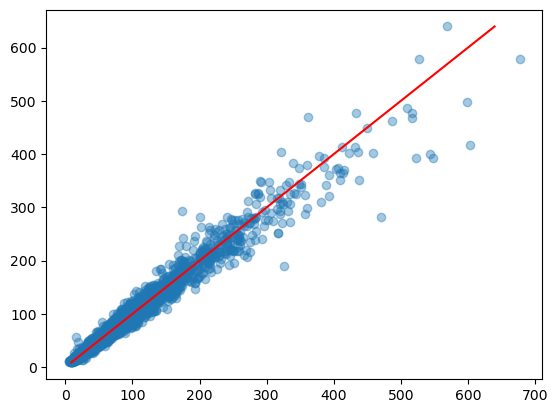

In [351]:
plt.scatter(result_grid_search["Actual"], result_grid_search["Predicted"], alpha = 0.4)
plt.plot([y_pred_grid_search.min(), y_pred_grid_search.max()], [y_pred_grid_search.min(), y_pred_grid_search.max()], color = "red")
plt.show()

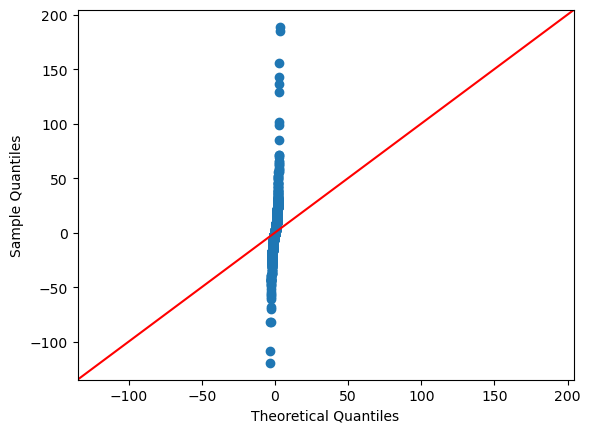

In [344]:
sm.qqplot(result_grid_search["Residuals"], line = "45")
plt.show()

### Final Results

In [352]:
final_predictions = {"Linear" : y_pred_linear_regression, "OLS" : y_pred_linear_regression_ols, "Ridge" : y_pred_ridge, "Lasso" : y_pred_lasso, "ElasticNet" : y_pred_elastic_net, "Polynomial" : y_pred_poly, "SVR" : y_pred_svr, "Random Forest" : y_pred_random_forest, "Bagging (Tree)" : y_pred_bagging_decision_tree, "Bagging (KNN)" : y_pred_bagging_knn, "Voting" : y_pred_voting, "Stacking" : y_pred_stacking, "Gradient Boosting" : y_pred_gradient_boosting, "XGBoost" : y_pred_xgboost, "LightGBM" : y_pred_lightgbm, "Tuned (GridSearch)" : y_pred_grid_search}

In [354]:
pd.DataFrame({name : [r2_score(y_test, pred), np.sqrt(mean_squared_error(y_test, pred)), mean_absolute_error(y_test, pred)] for name, pred in final_predictions.items()}, index = ["R2", "RMSE", "MAE"]).T.sort_values("R2", ascending = False)

,R2,RMSE,MAE
Tuned (GridSearch),0.964602,14.338536,7.811814
Gradient Boosting,0.964509,14.357305,7.816085
LightGBM,0.962635,14.731375,7.891887
Stacking,0.962439,14.770130,7.965864
Random Forest,0.962346,14.788368,8.079704
Bagging (Tree),0.961877,14.880098,8.066243
XGBoost,0.961144,15.022530,8.111810
Polynomial,0.961032,15.044128,8.449984
Voting,0.954170,16.315071,8.225696
OLS,0.944652,17.929310,9.636850


In [370]:
pd.DataFrame(zip(X_train_scaled.columns, gradient_boosting.feature_importances_), columns = ["Independent Variables", "Coefficient"])

,Independent Variables,Coefficient
0,population_density_per_km2,3.980648e-05
1,distance_to_major_road_m,1.802726e-04
2,industrial_units_within_5km,1.700373e-04
3,green_cover_pct,1.659258e-04
4,temperature_c,1.098747e-03
5,relative_humidity_pct,8.664272e-04
6,wind_speed_ms,1.200035e-03
7,wind_direction_deg,2.143316e-04
8,pressure_hpa,5.931690e-04
9,rainfall_mm,5.485415e-05
